> ## 🎤 강사 스크립트 · 이 강사용 노트북 사용법
>
> 이 노트북은 **학생용 `D21_VoiceAgent아키텍처_실습.ipynb`의 모든 셀을 그대로 담고**, 사이사이에 **인용 블록(왼쪽 세로줄)으로 된 🎤 강사 스크립트 셀**을 끼워 넣은 것입니다. 수업 화면에는 학생용을, 강사 화면에는 이 노트북을 띄우세요.
>
> | 표시 | 뜻 |
> |---|---|
> | 🎯 | 이 블록에서 학생이 가져가야 할 한 가지 |
> | 🗣️ | 그대로 읽어도 되는 강사 멘트 |
> | 🍎 | 일상 비유 |
> | 🖥️ | 화면 시연 |
> | ❓ | 학생에게 던지는 질문 → 예상 답 |
> | 🆘 | 빈칸에서 막힌 학생에게 단계별로 주는 힌트 |
> | ⚠️ | 자주 막히는 지점 · 오개념 · 오류 |
> | 🎧 | 반 전체가 같이 들을 소리 (스피커) |
> | ➡️ | 다음 블록으로 넘어가는 연결 멘트 |
>
> **오늘의 수업 방향**: 5주차 첫날, **"부품을 잇는 법"과 "시간을 다루는 법"** 을 배웁니다. 핵심 메시지는 **"음성 비서의 품질은 답의 내용만큼 '언제 말하기 시작하느냐'로 판단된다 → 단계별 예산을 세우고 → Streaming과 Endpointing으로 줄인다 → 구조(Cascade · S2S)는 서비스가 중요하게 여기는 것으로 고른다"** 입니다. 칠판에 쓰는 식은 **v2v = 말 끝 감지 + STT + LLM(첫 문장) + TTS(첫 소리)**, **p95**, **감지 시각 ≈ 말 끝 + 침묵 기준** 세 개입니다.
>
> > 🍎 **하루를 꿰는 비유: 식당 주방.** 주문 받기(VAD · STT) → 요리(LLM) → 서빙(TTS). 손님이 느끼는 건 '첫 접시가 나오기까지'. 코스 요리처럼 첫 접시부터 내면(Streaming) 기다림이 줄어든다.
>
> > 💡 정답 · 예상 출력 · 힌트는 이 노트북에만 있습니다. **학생에게 배포하지 마세요.**

> ## 🎤 강사 스크립트 · 하루 시간표와 수업 전 점검
>
> #### 하루 시간표 (50분 수업 + 10분 쉬는 시간)
> | 시간 | 교시 | 내용 | 빈칸 | 애니메이션 | 슬라이드 |
> |---|---|---|---|---|---|
> | 0:00–0:50 | 1교시 | 도입, Part 0 설치, Part 1 지형도, Part 2 부품 · Cascade v1 | 1 · 2 · 3 | D21-1, D21-2, D21-5, D21-6 | p.1 ~ 8 |
> | 1:00–1:50 | 2교시 | Part 3 Latency Budget · p50 · p95 · 답 길이 | 4 · 5 | D21-3, D21-7, D21-8 | p.9 ~ 11 |
> | 2:00–2:50 | 3교시 | Part 4 Streaming v2, Part 5 VAD Endpointing | 6 · 7 · 8 | D21-4, D21-5 | p.12 ~ 16 |
> | 3:00–3:50 | 4교시 | Part 6 Cascade vs S2S 선택, Part 7 정리 · 과제 | 9 | D21-9 | p.17 ~ 20 |
>
> **진도가 밀릴 때 줄이는 순서** (빈칸 실습은 줄이지 않습니다)
> 1. Part 3-1 답 길이 실험을 질문 1개로 (`QUESTIONS[:1]`)
> 2. Part 3 반복 측정을 1회로 (`range(1)`)
> 3. Part 5 두 번째 셀(잘린 STT 비교) 생략
>
> #### 수업 전 점검 (전날)
> - [ ] **T4 런타임**에서 처음부터 끝까지 한 번 실행(약 15 ~ 20분)하고 Part 2 v1 표, Part 3 판정표, Part 4 비교표, Part 5 침묵 기준 표를 캡처하세요.
> - [ ] 내려받는 모델: Whisper small · Qwen3-1.7B(약 3.5 GB) · MMS-TTS 한국어 · Silero VAD(pip 패키지 안에 포함). Part 0 직후 Part 2 첫 셀까지 바로 실행하게 하세요.
> - [ ] **LLM API 키는 오늘 필요 없음**. D22 준비 안내(Claude · OpenAI · Gemini 중 하나 이상, Colab 🔑 보안 비밀)를 수업 끝에 합니다.
> - [ ] 마이크 녹음은 선택(`USE_MIC`). 헤드셋 권장, 교실 소음이 크면 대역 목소리로.
> - [ ] [animation.html](https://imguru-mooc.github.io/AI_Voice/day21/animation.html), [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html) 탭을 열어 둡니다.
> - [ ] 학생 안내문:
>
> ```
> D21 실습 노트북: (Colab 링크) → [파일] → [Drive에 사본 저장]
> 런타임 → T4 GPU · 헤드셋(선택)
> 오늘은 API 키 없이 로컬 LLM(Qwen3)으로 진행
> 워크시트: https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html
> ```
>
> #### 오늘 학생들이 가장 많이 막히는 곳
> | 위치 | 증상 | 대응 |
> |---|---|---|
> | Part 2 첫 셀 | Qwen3 내려받기 느림 | 3 ~ 4분 정상. 그동안 Part 1 설명 |
> | Part 2 첫 셀 | `dtype` 인자 오류 | transformers 4.x 옛 런타임 → `torch_dtype=`로 바꾸거나 런타임 초기화 |
> | 빈칸 1 · 2 | 기다린 시간이 0.3초가 아님 | 빈칸 2에 숫자 500을 직접 쓴 경우 → 함수 인자 `min_silence_ms` |
> | 빈칸 3 | 대답이 길고 목록이 섞임 | 정상(작은 모델의 한계). `speakable()`이 기호를 지움, D22에서 큰 LLM으로 개선 |
> | Part 2-2 | '들은_말'이 질문과 다름 | 대역 목소리(VITS) 품질 · Whisper 오인식 → 디버깅 소재로 활용 |
> | 빈칸 6 | Streaming인데 v1과 시간이 같음 | `th.run()`을 쓴 경우 → `start()` |
> | Part 4 | v2가 오히려 느린 질문 | 답이 한 문장이면 이득 없음 + GPU를 LLM · TTS가 나눠 써서 약간 느려질 수 있음 → 정상 |

> ## 🎤 강사 스크립트 · 오늘의 비유 사전 (먼저 읽어 두기)
>
> | 개념 | 🍎 한 문장 비유 |
> |---|---|
> | Cascade | 쪽지를 넘기는 **통역사 셋** |
> | S2S | 처음부터 말로 알아듣는 **이중 언어 화자** |
> | VAD Endpointing | 상대가 **말을 끝냈는지 눈치** 보기 |
> | 침묵 기준 | 몇 초 조용하면 **내 차례**로 볼까 |
> | Latency Budget | 택배 **도착 약속 시간**을 단계별로 나누기 |
> | p95 | 100번 중 **가장 느린 5번** 직전 |
> | Cold start | 겨울 아침 **자동차 예열** |
> | Streaming | **코스 요리**: 첫 접시부터 낸다 |
> | TTFT | 요리사가 **첫 재료를 썰기 시작**하기까지 |
> | Barge-in | 말하는 도중 **"잠깐만요"** 에 멈추기 |

# D21. Voice Agent 아키텍처: Cascade vs Speech-to-Speech, Latency Budget  —  🎤 강사용

**음성 AI 전문가 과정 (160h) | 5주차 M5 LLM 연동 Voice Agent (Cascade 구조) | 4시간**

## 학습 목표
1. 음성 비서(Voice Agent)를 이루는 부품(VAD · STT · LLM · TTS)과 두 가지 설계 **Cascade(STT → LLM → TTS)** 와 **Speech-to-Speech(S2S)** 의 차이를 설명한다.
2. 지금까지 배운 부품(Silero VAD · Whisper · MMS 한국어 TTS)에 **소형 LLM(Qwen3, 로컬 · API 키 불필요)** 을 이어 **Cascade v1** 을 만들고, 단계마다 걸린 시간을 잰다.
3. **Latency Budget**(말이 끝난 뒤 첫 소리까지의 시간 예산)을 세우고, 측정값을 **p50 · p95** 로 읽는다.
4. LLM 토큰을 흘려보내며 **문장이 완성될 때마다 TTS** 하는 **Cascade v2 (Streaming)** 로 첫 소리 시간을 줄인다.
5. **VAD Endpointing**: 침묵 기준(`min_silence_duration_ms`)이 '기다림'과 '말 잘림' 사이에서 어떻게 줄다리기하는지 실험한다.
6. 서비스 상황에 따라 **Cascade · S2S · 중간형** 중 무엇을 고를지 근거를 들어 판단한다.

## 오늘의 실습 흐름
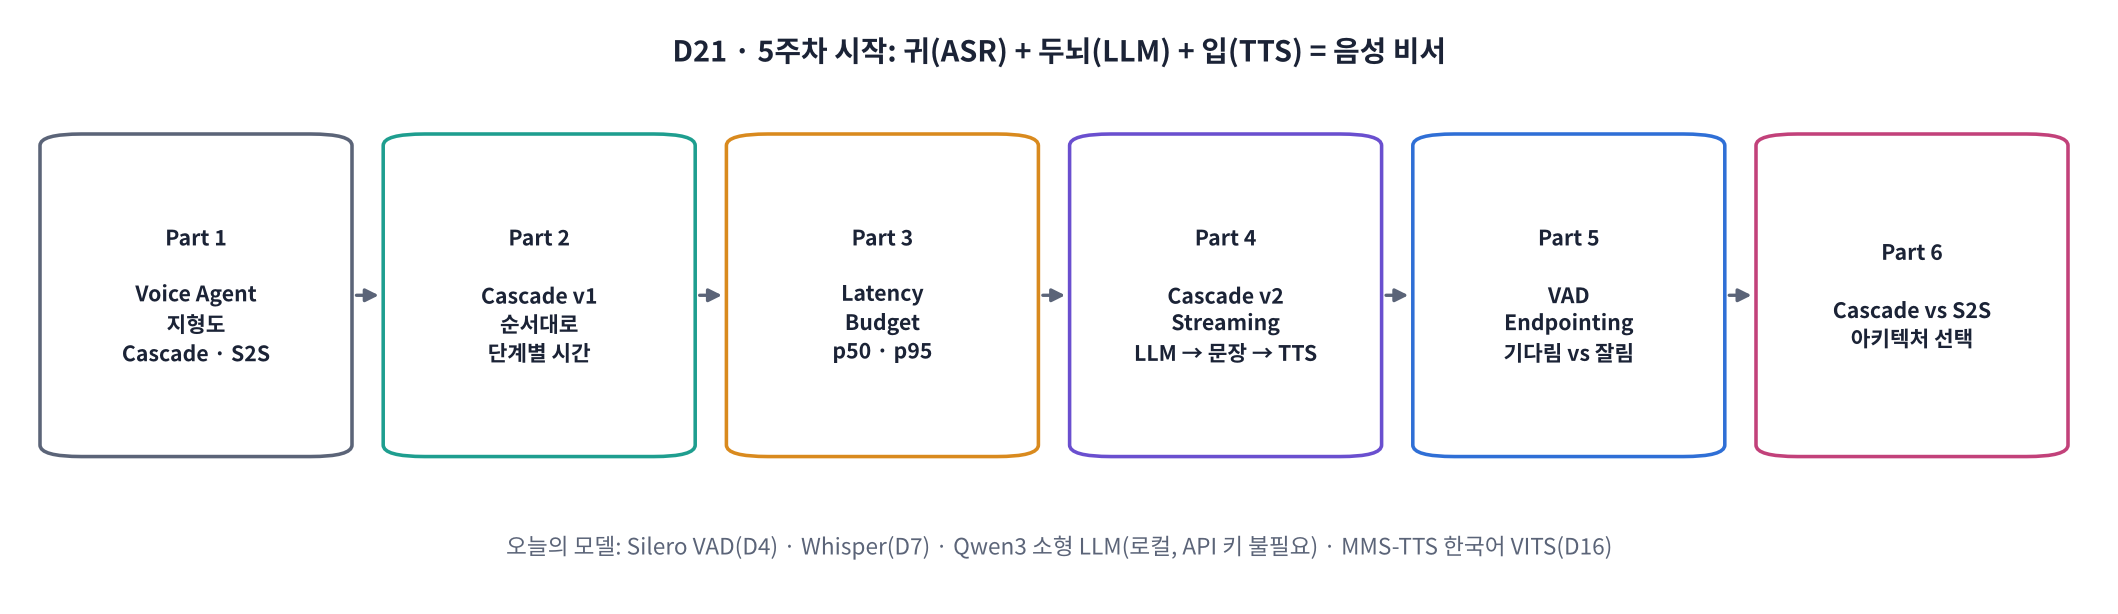

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | Voice Agent 지형도, 설치, 부품 준비(첫 호출 vs 데운 뒤), **Cascade v1** | Part 0 ~ 2, 워크시트 1교시 | 단계별 시간표 |
| 2교시 | **Latency Budget** 설계, p50 · p95, 답 길이와 지연 | Part 3, 워크시트 2교시 | 예산 대비 측정표 |
| 3교시 | **Cascade v2 Streaming**, VAD Endpointing 실험 | Part 4 ~ 5, 워크시트 3교시 | v1 vs v2 비교 · 침묵 기준 표 |
| 4교시 | **Cascade vs S2S** 아키텍처 선택, 정리 · 과제 | Part 6 ~ 7, 워크시트 4교시 | 아키텍처 선택표 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day21/animation.html) | 각 Part 설명을 볼 때 · 예산 설계기(D21-3) · 아키텍처 선택기(D21-9) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- ✏️ 표시가 있는 셀은 **직접 값을 바꿔** 실행하는 셀입니다(질문 문장, 침묵 기준, 예산, 가중치).

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 비서의 대답을 귀로 확인 |

> ⚙️ **런타임 → T4 GPU**. 모델 네 개(Silero VAD · Whisper · Qwen3 · MMS-TTS 한국어)를 씁니다. 처음 내려받기에 3 ~ 4분. **LLM API 키는 오늘 필요 없습니다**(D22에서 Claude · OpenAI · Gemini API를 연결합니다).
>
> 📜 Qwen3는 Apache 2.0, MMS-TTS 한국어(VITS)는 **CC BY-NC 4.0(비상업)** 이라 수업용으로만 씁니다. 마이크 녹음은 선택이며(`USE_MIC`), 녹음은 이 런타임 안에서만 쓰고 저장 · 공유하지 않습니다.

> 🎬 **애니메이션 D21-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#flow) — Part 1~7 로드맵과 시간 계획

> ## 🎤 강사 스크립트 · 도입  ⏱️ 5분
>
> 🎯 **5주차: 귀와 입 사이에 두뇌를 넣는다. 오늘은 구조와 시간.**
>
> 🗣️ "지금까지 귀(Whisper)와 입(TTS)을 만들었습니다. 이번 주에는 그 사이에 LLM을 넣어 대화하는 비서를 만듭니다. 그런데 음성 대화는 채팅과 결정적으로 다릅니다. 채팅은 3초 기다려도 괜찮지만, 전화에서 상대가 3초 동안 말이 없으면 '여보세요?'라고 하죠. 오늘은 **얼마나 빨리 말을 시작하느냐**를 설계합니다."
>
> 🖥️ [D21-1 오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#flow). 지난주 D20에서 잰 TTFA가 오늘 예산의 한 칸이 된다고 연결.

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D18 ~ D20과 같은 방식)**: Colab에 깔린 torch · transformers 버전을 그대로 고정하고, 오늘 새로 필요한 `silero-vad`(D4) · `uroman`(MMS TTS 로마자 변환) · `jiwer`만 추가합니다. `silero-vad`는 torch 말고는 의존성이 없어 안전합니다.

> ## 🎤 강사 스크립트 · Part 0  ⏱️ 4분
>
> 🖥️ 설치 → import. `silero-vad 6.x`, `GPU: Tesla T4` 확인. 설치가 짧으니 바로 Part 2 첫 셀(모델 내려받기)을 실행시키고 Part 1 설명.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "protobuf", "requests",
        "click", "filelock", "rich", "typer", "pydantic"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt silero-vad uroman jiwer
!apt-get -qq -y install ffmpeg > /dev/null
print("✅ 설치 완료")

In [ ]:
import os, re, io, json, time, copy, random, base64, subprocess, warnings, logging
from contextlib import contextmanager
from threading import Thread
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import jiwer
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000                                               # 오늘은 VAD · Whisper · MMS TTS 모두 16 kHz
CHUNK = 512                                              # Silero VAD가 한 번에 보는 크기 = 32 ms
print(" · ".join(f"{p} {md.version(p)}" for p in ["torch", "transformers", "silero-vad"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 ⚠️ T4로 바꾸세요")

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    display(Audio(y, rate=sr))

def silence(sec):
    return np.zeros(int(sec * SR), np.float32)

def sync():                                              # GPU 작업이 끝날 때까지 기다려야 시간이 정확
    if GPU: torch.cuda.synchronize()

# D16 정규화 (숫자 → 읽는 말)
DIGITS = "영일이삼사오육칠팔구"
def sino(n):
    if n == 0: return "영"
    out = ""
    for big in ["", "만", "억", "조"]:
        chunk, n = n % 10000, n // 10000; s = ""
        for i, unit in enumerate(["", "십", "백", "천"]):
            d, chunk = chunk % 10, chunk // 10
            if d: s = ("" if d == 1 and i > 0 else DIGITS[d]) + unit + s
        if s: out = ("" if s == "일" and big == "만" else s) + big + out
        if n == 0: break
    return out
ONES = ["", "한", "두", "세", "네", "다섯", "여섯", "일곱", "여덟", "아홉"]
TENS = ["", "열", "스물", "서른", "마흔", "쉰", "예순", "일흔", "여든", "아흔"]
def native(n): return sino(n) if not 0 < n < 100 else ("스무" if n == 20 else TENS[n // 10] + ONES[n % 10])
NATIVE_COUNTERS = ["시간", "개", "명", "살", "마리", "권", "잔", "병", "장", "달", "시"]
def read_number(s):
    s = s.replace(",", "")
    if "." in s:
        a, b = s.split(".", 1); return sino(int(a)) + "점" + "".join(DIGITS[int(c)] for c in b)
    return sino(int(s))
def normalize_ko(t):
    t = re.sub(r"(\d+)\s*(" + "|".join(NATIVE_COUNTERS) + ")", lambda m: native(int(m.group(1))) + " " + m.group(2), t)
    t = re.sub(r"(\d[\d,]*(?:\.\d+)?)\s*%", lambda m: read_number(m.group(1)) + " 퍼센트", t)
    t = re.sub(r"\d[\d,]*(?:\.\d+)?", lambda m: read_number(m.group(0)), t)
    return re.sub(r"\s+", " ", t).strip()

## Part 1. Voice Agent 지형도: Cascade vs Speech-to-Speech

> 💬 **쉽게 말하면**: 음성 비서는 **귀(STT) · 두뇌(LLM) · 입(TTS)** 에 **"말이 끝났나?"를 판단하는 문지기(VAD)** 를 더한 것입니다. 이 부품들을 차례로 잇는 것이 **Cascade**, 소리를 듣고 바로 소리로 답하는 하나의 큰 모델이 **Speech-to-Speech(S2S)** 입니다.

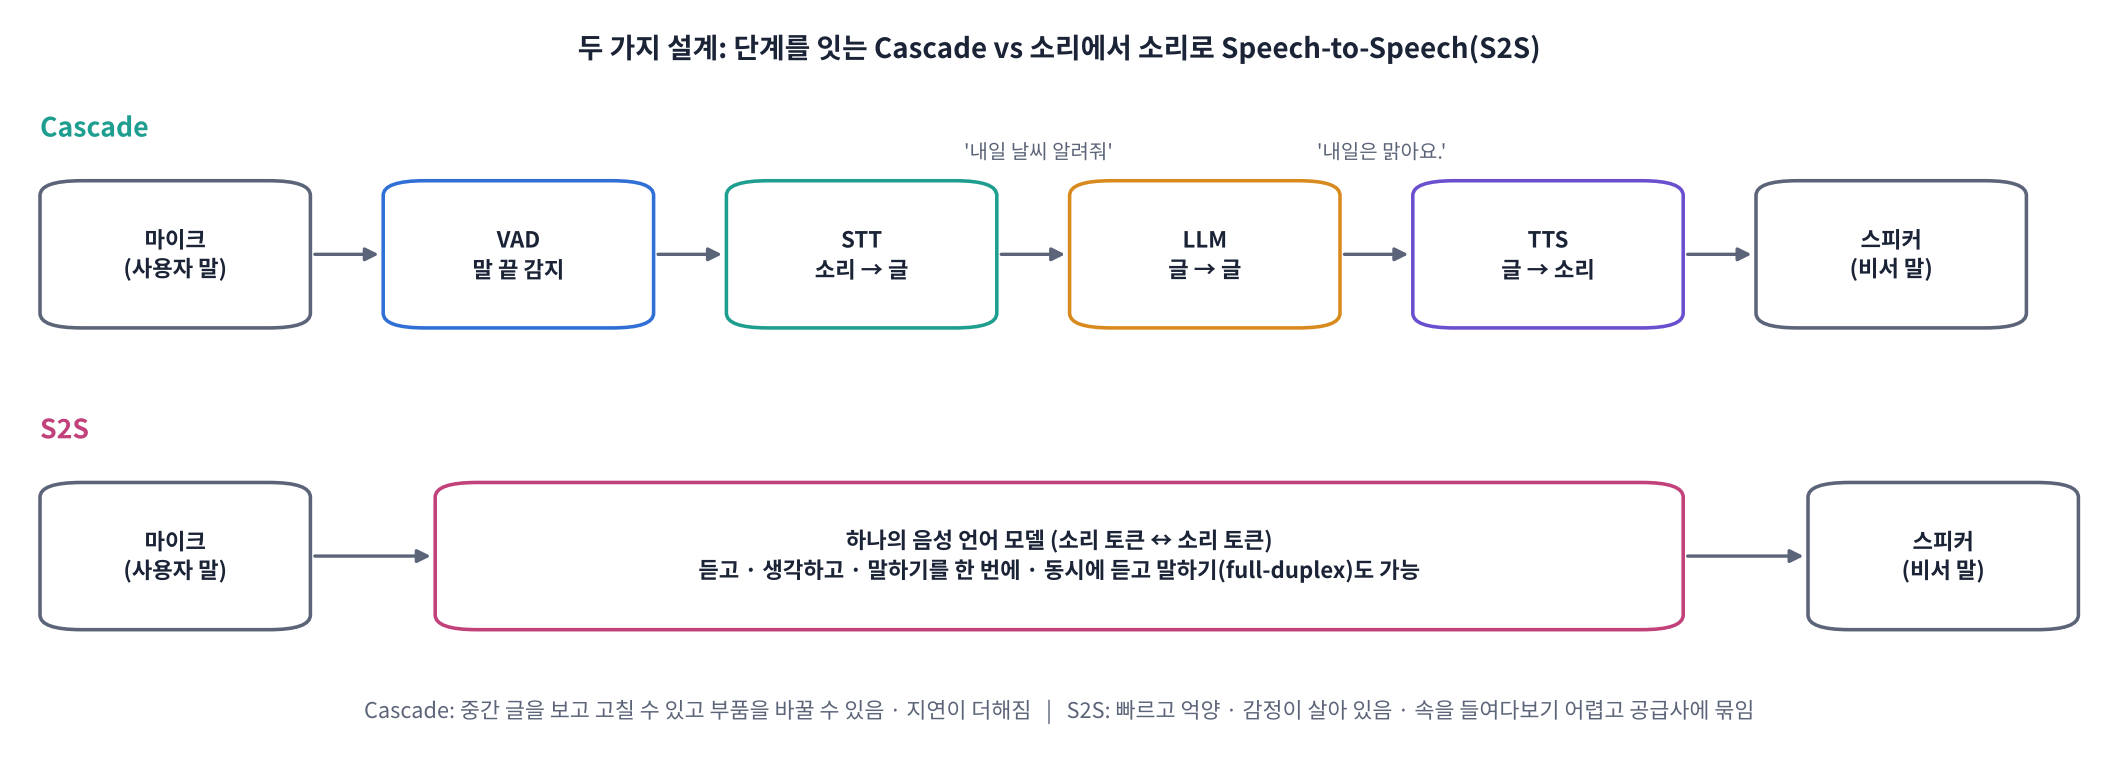

👣 **Cascade 한 턴 한 단계씩**
1. 🎤 사용자가 말함 → **VAD**가 32 ms마다 "지금 말소리인가?"를 판단
2. 말소리가 끝나고 **침묵이 정해진 시간만큼 이어지면** "말 끝(end of turn)"으로 판단 → 여기까지가 한 턴
3. **STT(Whisper)** 가 그 구간을 글로 바꿈: "내일 서울 날씨 어때?"
4. **LLM**이 대화 이력 + 시스템 지시(짧게 · 구어체)를 보고 답을 글로 씀
5. **TTS**가 답을 소리로 → 🔊 재생

| 구분 | Cascade | Speech-to-Speech (S2S) |
|---|---|---|
| 구조 | VAD → STT → LLM → TTS (부품 4개) | 음성 언어 모델 1개 (소리 ↔ 소리) |
| 대표 예 | 오늘 실습 · Pipecat · LiveKit Agents (6주차) | OpenAI Realtime 계열 · Google Gemini Live 계열 · 오픈 모델 Moshi (D30) |
| 강점 | 중간 글을 보고 고칠 수 있음, 부품 교체, 강한 Tool Calling, 한국어 특화 부품 | 지연이 짧음, 억양 · 감정 · 웃음을 듣고 표현, 끼어들기 · 맞장구에 자연스러움 |
| 약점 | 단계마다 지연이 더해짐, 감정 정보가 글로 바뀌며 사라짐 | 속이 보이지 않음, 공급사에 묶임, 분당 요금, 언어 지원 확인 필요 |

> 🍎 **비유: 통역사 셋 vs 이중 언어 화자.** Cascade는 '받아쓰는 사람 → 답을 쓰는 사람 → 읽어 주는 사람'이 쪽지를 넘기는 것, S2S는 처음부터 말로 알아듣고 말로 답하는 한 사람입니다. 쪽지가 남으니 Cascade는 **무슨 일이 있었는지 확인하기 쉽고**, S2S는 **쪽지를 넘기는 시간이 없어 빠르지만** 무엇을 생각했는지 보기 어렵습니다.

> 📐 **핵심 식 하나: voice-to-voice 지연 = 말 끝 감지 + STT + LLM(첫 문장) + TTS(첫 소리) + 네트워크** — 사람끼리 대화의 틈은 보통 0.2 ~ 0.3초, 음성 비서는 **약 0.8초 안쪽**이면 자연스럽고 1.2초를 넘으면 '고장 난 듯'하게 느낀다는 보고가 많습니다(업계 보고 예, 측정마다 다름).

> 🎬 **애니메이션 D21-2:** [Cascade vs S2S 흐름](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#arch) — 한 턴이 두 구조를 지나가는 모습과 단계별 시간 비교

**❓ 생각해 보기**: Cascade에서 '사용자가 화난 목소리로 말했다'는 정보는 어디서 사라질까요? 되살리려면?

<details>
<summary>답 보기</summary>

**STT 단계**에서 소리가 글로 바뀌며 억양 · 크기 · 떨림이 사라집니다. LLM은 '환불해 주세요'라는 글만 봅니다. 되살리는 방법: ① 감정 · 화자 인식 모델의 결과를 LLM에 **태그로 함께 전달**(예: `[감정: 화남]`) ② STT 대신 **소리를 직접 듣는 음성 LLM**을 쓰는 중간형(half-cascade) ③ 처음부터 S2S. 1 → 3으로 갈수록 자연스럽지만 제어 · 디버깅이 어려워집니다.

</details>

> ## 🎤 강사 스크립트 · Part 1 지형도  ⏱️ 12분
>
> 🎯 **Cascade = 부품 4개를 잇는다, S2S = 하나의 모델이 소리에서 소리로.**
>
> 🖥️ [D21-2 Cascade vs S2S 흐름](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#arch): 한 턴이 지나가는 애니메이션 → '쪽지(글)'가 남는 곳 강조.
>
> 🗣️ "2026년 지금 상용 S2S는 OpenAI Realtime 계열, Google Gemini Live 계열이 대표적이고, 오픈 모델로 Kyutai Moshi가 있습니다. 6주차 D30에서 직접 비교합니다. 그런데 실제 서비스의 상당수는 여전히 Cascade입니다. 왜일까요?"
>
> ❓ → 기록 · 디버깅 · 부품 교체 · 도구 호출 · 한국어 특화 · 비용 · 개인정보.
>
> ❓ 생각해 보기(화난 목소리 정보는 어디서 사라지나) → STT. 감정 태그 · 음성 LLM · S2S.
>
> ⚠️ 지연 숫자(0.2 ~ 0.3초 대화 틈, 0.8 · 1.2초)는 **업계 보고 예**라고 분명히 말하세요. 측정 방법마다 다릅니다.

## Part 2. Cascade v1: 부품을 차례로 잇고 단계마다 시간 재기

> 💬 **쉽게 말하면**: 오늘의 부품 네 개를 불러오고, 한 턴을 **순서대로**(앞 단계가 다 끝나야 다음 단계) 처리하는 가장 단순한 비서를 만듭니다. 그리고 **어디서 시간이 가장 많이 드는지** 잽니다.

| 부품 | 모델 | 배운 날 | 오늘 쓰는 곳 |
|---|---|---|---|
| VAD | Silero VAD (`VADIterator`, 32 ms 단위) | D4 | 말 끝 감지 |
| STT | Whisper small (GPU) / tiny (CPU) | D7 · D8 | 소리 → 글 |
| LLM | **Qwen3-1.7B** (GPU) / 0.6B (CPU), 생각 모드 끔 | 새로 | 글 → 글 |
| TTS | MMS-TTS 한국어 (VITS) | D16 | 글 → 소리 |

> ⚠️ **첫 호출은 느립니다(cold start)**. GPU 메모리 할당 · 커널 준비 때문에 첫 번째 실행은 두 번째보다 몇 배 느립니다. 서비스는 서버를 켤 때 **미리 한 번 돌려 데워 둡니다(warm-up)**. 아래 셀이 두 번을 비교합니다.

> ## 🎤 강사 스크립트 · Part 2 부품 소개  ⏱️ 3분
>
> 🗣️ "새 부품은 LLM 하나뿐입니다. Qwen3-1.7B는 T4에 올라가는 작은 모델이라 답의 품질은 기대하지 마세요. 오늘의 목적은 **구조와 시간**입니다. 품질은 D22에서 큰 API 모델로 올립니다."

In [ ]:
# 부품 네 개 준비 + 첫 호출(cold) vs 두 번째(warm) 시간
from silero_vad import load_silero_vad, VADIterator
from transformers import (AutoTokenizer, AutoModelForCausalLM, TextIteratorStreamer,
                          WhisperProcessor, WhisperForConditionalGeneration, VitsModel)
import uroman as ur

vad = load_silero_vad()

ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

LLM_NAME = "Qwen/Qwen3-1.7B" if GPU else "Qwen/Qwen3-0.6B"
tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=torch.float16 if GPU else torch.float32).to(DEVICE).eval()

tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()

def stt(y):
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    sync()
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def speakable(text):                                     # 소리로 읽기 좋게: 마크다운 · 이모지 · 괄호 지우고 숫자는 읽는 말로
    text = re.sub(r"<think>.*?</think>|</?think>", "", text, flags=re.S)
    text = re.sub(r"[*#`>\[\]()_~]|[\U0001F300-\U0001FAFF]", "", text)
    return normalize_ko(text).strip() or "죄송해요, 다시 말씀해 주세요."

def tts(text, seed=0):
    set_seed(seed)
    enc = tts_tok(U.romanize_string(speakable(text)), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        y = to_np(tts_model(**enc).waveform[0])
    sync()
    return y

probe = librosa.tone(220, sr=SR, duration=1.0).astype(np.float32) * 0.1
rows = []
for name, fn in [("STT", lambda: stt(probe)), ("TTS", lambda: tts("안녕하세요.")),
                 ("LLM", lambda: llm.generate(**tok("안녕", return_tensors="pt").to(DEVICE), max_new_tokens=8, do_sample=False))]:
    times = []
    for _ in range(2):
        t = time.perf_counter(); fn(); sync(); times.append(time.perf_counter() - t)
    rows.append(dict(부품=name, 첫_호출_초=round(times[0], 3), 두번째_초=round(times[1], 3), 배=round(times[0] / max(times[1], 1e-6), 1)))
display(pd.DataFrame(rows))
print("LLM:", LLM_NAME, "· STT:", ASR_NAME, "· VAD: Silero · TTS: MMS-TTS 한국어")

> ## 🎤 강사 스크립트 · 부품 준비 · cold vs warm  ⏱️ 5분
>
> ✅ 예상 출력: 표 3줄, `첫_호출_초`가 `두번째_초`보다 2 ~ 20배(특히 LLM · STT).
>
> 🍎 겨울 아침 자동차 예열. "서버를 켜자마자 첫 손님이 오면 그 손님만 느립니다. 그래서 서비스는 시작할 때 가짜 요청으로 한 번 데웁니다."
>
> ⚠️ `dtype=` 오류가 나면 옛 transformers → `torch_dtype=`.

### 2-1. ✏️ 사용자의 말 준비
`USE_MIC = True`면 질문 하나를 직접 녹음하고(5초), `False`면 TTS로 만든 **대역 사용자 목소리**(음높이를 낮춰 비서 목소리와 구분)를 씁니다. 실제처럼 **말 앞 0.8초 · 뒤 1.5초에 침묵**을 붙입니다. 뒤 침묵이 있어야 VAD가 '말 끝'을 알 수 있습니다.

> ## 🎤 강사 스크립트 · 사용자 말 준비  ⏱️ 4분
>
> 🗣️ "뒤에 1.5초 침묵을 붙이는 이유? VAD는 '조용해진 뒤 일정 시간'이 지나야 말이 끝났다고 압니다. 침묵이 없으면 영원히 기다립니다."
>
> ⚠️ 녹음은 선택. 녹음 학생은 말한 뒤 **조용히 기다리게** 하세요(5초 고정 녹음).

In [ ]:
USE_MIC = False                                          # ✏️ True: 첫 질문을 내 목소리로 녹음 (헤드셋 권장)
QUESTIONS = ["내일 서울 날씨는 어때?",                   # ✏️ 질문을 바꿔 보세요
             "점심 메뉴 하나만 추천해 줘.",
             "회의를 3시 30분으로 옮겨 줄래?"]

RECORD_JS = '''
window.recordOne = async function(text, sec) {
  const box = document.createElement('div');
  box.style.cssText = 'font:18px sans-serif;padding:12px 14px;border:2px solid #1E9E8F;border-radius:10px;margin:6px 0';
  document.body.appendChild(box);
  box.innerHTML = '🎙️ 준비 … <b>' + text + '</b>';
  const stream = await navigator.mediaDevices.getUserMedia({audio: true});
  await new Promise(r => setTimeout(r, 1000));
  const rec = new MediaRecorder(stream); const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.start(); box.innerHTML = '🔴 녹음 중 (' + sec + '초) — 말한 뒤 조용히 기다리세요: <b>' + text + '</b>';
  await new Promise(r => setTimeout(r, sec * 1000));
  rec.stop(); await new Promise(r => rec.onstop = r); stream.getTracks().forEach(t => t.stop());
  box.innerHTML = '✅ ' + text;
  const b = new Uint8Array(await new Blob(chunks).arrayBuffer()); let s = '';
  for (let i = 0; i < b.length; i += 8192) s += String.fromCharCode.apply(null, b.subarray(i, i + 8192));
  return btoa(s);
};
'''
try:
    from google.colab import output as colab_output
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def user_voice(text, seed=0):                            # 대역 사용자: TTS 목소리를 3반음 낮춤
    y = librosa.effects.pitch_shift(tts(text, seed=seed + 50), sr=SR, n_steps=-3)
    return np.concatenate([silence(0.8), y, silence(1.5)]).astype(np.float32)

USER_AUDIO = []
for i, q in enumerate(QUESTIONS):
    if i == 0 and USE_MIC and IN_COLAB:
        from IPython.display import Javascript
        display(Javascript(RECORD_JS))
        b64 = colab_output.eval_js(f"recordOne({json.dumps(q)}, 5)")
        open("q0.webm", "wb").write(base64.b64decode(b64))
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "q0.webm", "-ac", "1", "-ar", str(SR), "q0.wav"], check=True)
        y, _ = sf.read("q0.wav", dtype="float32"); os.remove("q0.webm"); os.remove("q0.wav")
        y = np.concatenate([y, silence(1.5)]); src = "내 녹음"
    else:
        y, src = user_voice(q, i), "대역 목소리"
    USER_AUDIO.append(dict(text=q, y=y, src=src))
    play(y, SR, f"사용자 {i + 1} ({src}): {q}")

### 🧩 빈칸 실습 1 · 2: 시간 재는 도구와 '말 끝' 감지
- 빈칸 1: `stage()`는 `with` 블록 안의 코드가 걸린 시간을 `T[이름]`에 적습니다. **시작 시각을 담은 변수**를 넣으세요.
- 빈칸 2: Silero `VADIterator`는 말소리 뒤에 침묵이 **`min_silence_duration_ms`** 만큼 이어지면 `{"end": 샘플 위치}`를 돌려줍니다. 함수 인자로 받은 **침묵 기준 변수**를 넣으세요.

👣 **VADIterator 한 단계씩**: 32 ms(512샘플)씩 넣음 → 말소리 확률 ≥ 0.5면 '말하는 중' → 확률이 떨어진 시점을 기억 → 그 뒤로 침묵이 기준만큼 쌓이면 `end` 이벤트. 그래서 **감지 시각 − 실제 말 끝 ≈ 침묵 기준**입니다.

> 🎬 **애니메이션 D21-5:** [VAD 말 끝 감지](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#vad) — 침묵 기준을 바꿔 감지 시각과 말 잘림 보기

> ## 🎤 강사 스크립트 · 빈칸 실습 1 · 2  ⏱️ 10분
>
> 🆘 빈칸 1: "바로 위 줄에서 시작 시각을 어디에 담았나요?" → `t_begin`
> 🆘 빈칸 2: "함수가 인자로 받은 침묵 기준 이름" → `min_silence_ms` (숫자를 직접 쓰지 않기)
>
> ✅ 예상 출력: `stage: {'잠깐 쉬기': 0.05…}`, 말 끝 이벤트 1개 이상, `기다린 시간: 0.32초 (침묵 기준 0.3초)`, `✅`.
>
> 🖥️ [D21-5 VAD 말 끝 감지](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#vad): 침묵 기준 슬라이더 → 감지 시각이 그만큼 밀림.
>
> ❓ "왜 0.30이 아니라 0.32일까요?" → 32 ms 단위로 보기 때문(512샘플).

In [ ]:
# 🧩 빈칸 실습 1 · 2
@contextmanager
def stage(T, name):
    t_begin = time.perf_counter()
    yield
    sync()
    T[name] = time.perf_counter() - ____                                                  # 빈칸 1

def endpoint(y, min_silence_ms=500):
    # 소리를 32 ms씩 '실시간처럼' 넣으며 말 끝 이벤트를 모음 (detected: 감지한 시각, speech_end: 실제 말이 끝난 시각)
    it = VADIterator(vad, sampling_rate=SR, min_silence_duration_ms=____)                 # 빈칸 2
    ends = []
    for i in range(0, len(y) - CHUNK + 1, CHUNK):
        ev = it(torch.from_numpy(np.ascontiguousarray(y[i:i + CHUNK])))
        if ev and "end" in ev:
            ends.append(dict(detected=(i + CHUNK) / SR, speech_end=ev["end"] / SR))
    it.reset_states()
    return ends

T = {}
with stage(T, "잠깐 쉬기"):
    time.sleep(0.05)
ev = endpoint(USER_AUDIO[0]["y"], 300)
print("stage:", {k: round(v, 3) for k, v in T.items()})
print("말 끝 이벤트:", [{k: round(v, 3) for k, v in e.items()} for e in ev])
wait = ev[0]["detected"] - ev[0]["speech_end"] if ev else None
print(f"말 끝 → 감지까지 기다린 시간: {wait:.3f}초 (침묵 기준 0.3초)" if ev else "말 끝을 못 찾음 → 녹음에 말소리가 있는지 확인")
check(0.045 < T["잠깐 쉬기"] < 0.3 and wait is not None and 0.27 < wait < 0.42 and endpoint(silence(2.0)) == [],
      hint="빈칸 1 = t_begin, 빈칸 2 = min_silence_ms")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
T[name] = time.perf_counter() - t_begin
it = VADIterator(vad, sampling_rate=SR, min_silence_duration_ms=min_silence_ms)
```

**해설**: `time.perf_counter()`는 시계 바늘 대신 **아주 정밀한 초시계**입니다. 시작 시각을 기억했다가 끝 시각에서 빼면 걸린 시간이 됩니다. GPU는 일을 '맡겨 두고' 바로 돌아오므로, 빼기 전에 `sync()`(= `torch.cuda.synchronize()`)로 실제로 끝날 때까지 기다려야 시간이 정확합니다(D17 · D20). VAD는 침묵이 기준만큼 이어져야 '끝'이라고 판단하므로, 감지 시각은 실제 말 끝보다 **침묵 기준 + 약 30 ms(32 ms 단위로 보기 때문)** 늦습니다. 강사 실측(JFK 연설): 기준 300 ms → 322 ms, 500 ms → 514 ms. 침묵만 있는 소리에서는 말 끝 이벤트가 없어야 정상입니다.

</details>

### 🧩 빈칸 실습 3: 음성 비서용 시스템 지시
LLM에게 주는 메시지는 **역할(role)** 이 붙은 목록입니다. 맨 앞에는 모든 대화에 적용되는 규칙을 담은 **시스템 메시지**를 둡니다. 음성 비서의 규칙은 글 채팅과 다릅니다: **짧게(1 ~ 2문장) · 구어체 · 목록 · 마크다운 · 이모지 금지**. 읽을 수 없는 것은 소리로 낼 수 없고, 답이 길수록 늦어지기 때문입니다(Part 3에서 측정). 빈칸에는 **시스템 메시지의 role 이름**을 넣으세요.

> 💡 Qwen3는 답하기 전에 길게 '생각'하는 모드가 있습니다. 음성 비서는 기다릴 수 없으므로 `enable_thinking=False`로 끕니다.

> ## 🎤 강사 스크립트 · 빈칸 실습 3  ⏱️ 8분
>
> 🆘 "규칙을 담는 메시지의 역할 이름, 따옴표 포함" → `"system"`
>
> ✅ 예상 출력: `<|im_start|>system … <|im_start|>assistant <think></think>` 형태의 프롬프트, 짧은 대답 1줄, `✅`.
>
> 🗣️ "프롬프트 맨 끝의 빈 `<think></think>`가 '생각 모드 끔'입니다. 생각 모드를 켜면 답하기 전에 수백 토큰을 생각하느라 몇 초가 사라집니다."
>
> ❓ "음성 비서 지시에 '목록 금지'를 넣는 이유?" → 소리로 읽을 수 없고, 길어져 늦어짐.

In [ ]:
# 🧩 빈칸 실습 3
VOICE_SYSTEM = ("너는 한국어 음성 비서야. 네 대답은 소리로 읽힌다. 한두 문장, 60자 안쪽의 짧은 구어체로 답해. "
                "목록, 표, 마크다운, 이모지, 괄호는 쓰지 마. 모르는 것은 모른다고 짧게 말해.")
MAX_NEW = 80                                             # 답 길이 상한 (토큰)

def build_messages(user_text, history=(), system=VOICE_SYSTEM):
    return [{"role": "____", "content": system}, *history, {"role": "user", "content": user_text}]   # 빈칸 3

def llm_inputs(messages):
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    return tok(text, return_tensors="pt").to(DEVICE)

def llm_reply(messages, max_new_tokens=MAX_NEW):
    enc = llm_inputs(messages)
    with torch.no_grad():
        out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, repetition_penalty=1.1)
    sync()
    new = out[0, enc["input_ids"].shape[1]:]
    return re.sub(r"<think>.*?</think>", "", tok.decode(new, skip_special_tokens=True), flags=re.S).strip(), len(new)

msgs = build_messages("안녕? 너는 누구야?")
print(tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)[:400])
reply, n_tok = llm_reply(msgs)
print(f"\n🤖 ({n_tok}토큰) {reply}")
check(msgs[0]["role"] == "system" and msgs[-1]["role"] == "user" and isinstance(reply, str) and n_tok > 0,
      hint='빈칸 3 = "system"')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return [{"role": "system", "content": system}, *history, {"role": "user", "content": user_text}]
```

**해설**: 채팅 LLM의 메시지 역할은 보통 `system`(규칙) · `user`(사용자) · `assistant`(모델의 이전 답) 세 가지입니다. `apply_chat_template`이 이 목록을 모델이 학습한 형식(Qwen은 `<|im_start|>system ... <|im_end|>`)의 글로 바꿔 줍니다. 대화를 이어 가려면 이전 턴의 `user` · `assistant` 메시지를 `history`에 차례로 쌓습니다(D22에서 이력 관리). 음성용 시스템 지시는 **짧게 · 구어체 · 읽을 수 없는 기호 금지**가 핵심이고, 그래도 기호가 섞이면 `speakable()`이 TTS 전에 한 번 더 지웁니다.

</details>

### 2-2. Cascade v1 한 턴
`cascade_v1()`은 ① VAD로 **첫 번째 '말 끝'** 을 찾고(실제 비서처럼 그 순간 바로 답을 준비) ② 그때까지의 소리를 STT ③ LLM ④ TTS를 **순서대로** 처리합니다. 사용자가 느끼는 지연(voice-to-voice)은 네 단계의 합입니다.

> ## 🎤 강사 스크립트 · Cascade v1  ⏱️ 2분
>
> 🗣️ "이제 네 부품을 순서대로 잇습니다. 실제 비서처럼 **첫 번째** '말 끝'에서 바로 답을 준비합니다. 이 결정이 Part 5에서 문제가 됩니다."

In [ ]:
def cascade_v1(y, min_silence_ms=500, history=()):
    T = {}
    ends = endpoint(y, min_silence_ms)
    end = ends[0] if ends else dict(detected=len(y) / SR, speech_end=len(y) / SR)
    T["endpoint"] = end["detected"] - end["speech_end"]                  # 말 끝을 확신하려고 기다린 시간
    turn = y[: int(end["detected"] * SR)]
    with stage(T, "stt"):
        heard = stt(turn)
    with stage(T, "llm"):
        reply, n_tok = llm_reply(build_messages(heard, history))
    with stage(T, "tts"):
        out = tts(reply)
    T["v2v"] = T["endpoint"] + T["stt"] + T["llm"] + T["tts"]
    return dict(heard=heard, reply=reply, tokens=n_tok, audio=out, T=T)

V1 = []
for u in USER_AUDIO:
    r = cascade_v1(u["y"])
    V1.append(dict(질문=u["text"], 들은_말=r["heard"], 대답=r["reply"], 토큰=r["tokens"], **{k: round(v, 3) for k, v in r["T"].items()}))
    play(r["audio"], SR, f"🤖 {r['reply'][:40]}")
V1 = pd.DataFrame(V1)
display(V1)

ax = V1[["endpoint", "stt", "llm", "tts"]].plot.barh(stacked=True, figsize=(10, 2.6), color=["tab:blue", "tab:cyan", "tab:orange", "tab:purple"])
ax.set_yticklabels([f"Q{i + 1}" for i in range(len(V1))]); ax.invert_yaxis(); ax.axvline(0.8, color="green", ls="--"); ax.axvline(1.2, color="red", ls="--")
ax.set_xlabel("seconds after user stopped talking (v1, sequential)"); plt.tight_layout(); plt.show()

> ## 🎤 강사 스크립트 · v1 실행 · 결과 읽기  ⏱️ 8분
>
> ✅ 예상 출력(T4): endpoint ≈ 0.51, stt 0.2 ~ 0.4, llm 0.8 ~ 2.5(토큰 수에 비례), tts 0.05 ~ 0.2, v2v 1.6 ~ 3.5초. 막대 그래프가 대부분 빨간 선(1.2초)을 넘음.
>
> 🎧 대답 하나를 스피커로. "1.5 ~ 3초 침묵 뒤 대답 — 전화라면 어떤가요?"
>
> 🖥️ [D21-6 턴 테이킹](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#turn): 사람 대화의 틈과 비교.
>
> ❓ 생각해 보기('들은_말'이 다르면) → Cascade의 장점 = 어느 단계가 틀렸는지 보임.

**결과 읽기**
- 가장 긴 막대는 대개 **LLM**입니다. LLM은 토큰을 하나씩 만들기 때문에 **답이 길수록 오래** 걸립니다(`토큰` 열과 비교).
- 그다음은 **endpoint(말 끝 기다리기)** 입니다. 아무리 빨라도 0.5초는 '침묵을 확인'하느라 그냥 기다립니다.
- STT · TTS는 짧은 문장이라 T4에서 각각 0.1 ~ 0.5초 정도입니다.
- 초록 점선(0.8초) · 빨간 점선(1.2초)과 비교해 보세요. v1은 대부분 빨간 선을 넘습니다 → Part 3 · 4에서 줄입니다.

**❓ 생각해 보기**: '들은_말' 열이 질문과 다르게 나온 경우가 있다면, 비서의 대답은 어떻게 될까요? Cascade의 장점과 어떻게 연결되나요?

<details>
<summary>답 보기</summary>

STT가 틀리면 LLM은 **틀린 질문에 그럴듯하게** 답합니다(쓰레기가 들어가면 쓰레기가 나옴). 하지만 Cascade는 '들은_말'이 글로 남기 때문에 **어느 단계가 틀렸는지 바로 보입니다**(STT 문제인지 LLM 문제인지). 대책: ① 도메인 용어로 STT 개선(3주차 Fine-tuning) ② LLM 지시에 '알아듣기 어려우면 되물어'를 추가 ③ 중요한 작업(송금 · 예약)은 '○○로 예약할까요?'처럼 확인 질문.

</details>

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html)** — Voice Agent 부품, Cascade vs S2S, VAD 말 끝 감지, 첫 호출(cold start), 시스템 지시, 측정 도구
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 1교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html). 자주 틀리는 문항: **S2S의 약점(디버깅)**, **감지 시각 ≈ 말 끝 + 침묵 기준**, **cold start**.

## Part 3. Latency Budget: 시간 예산을 세우고 p50 · p95로 읽기

> 💬 **쉽게 말하면**: "1초 안에 대답"이라는 목표를 정했다면, 그 1초를 **단계마다 나눠 주는 것**이 Latency Budget입니다. 가계부처럼 항목별 한도를 정해 두면, 측정했을 때 **어느 항목이 예산을 넘었는지** 바로 보입니다.

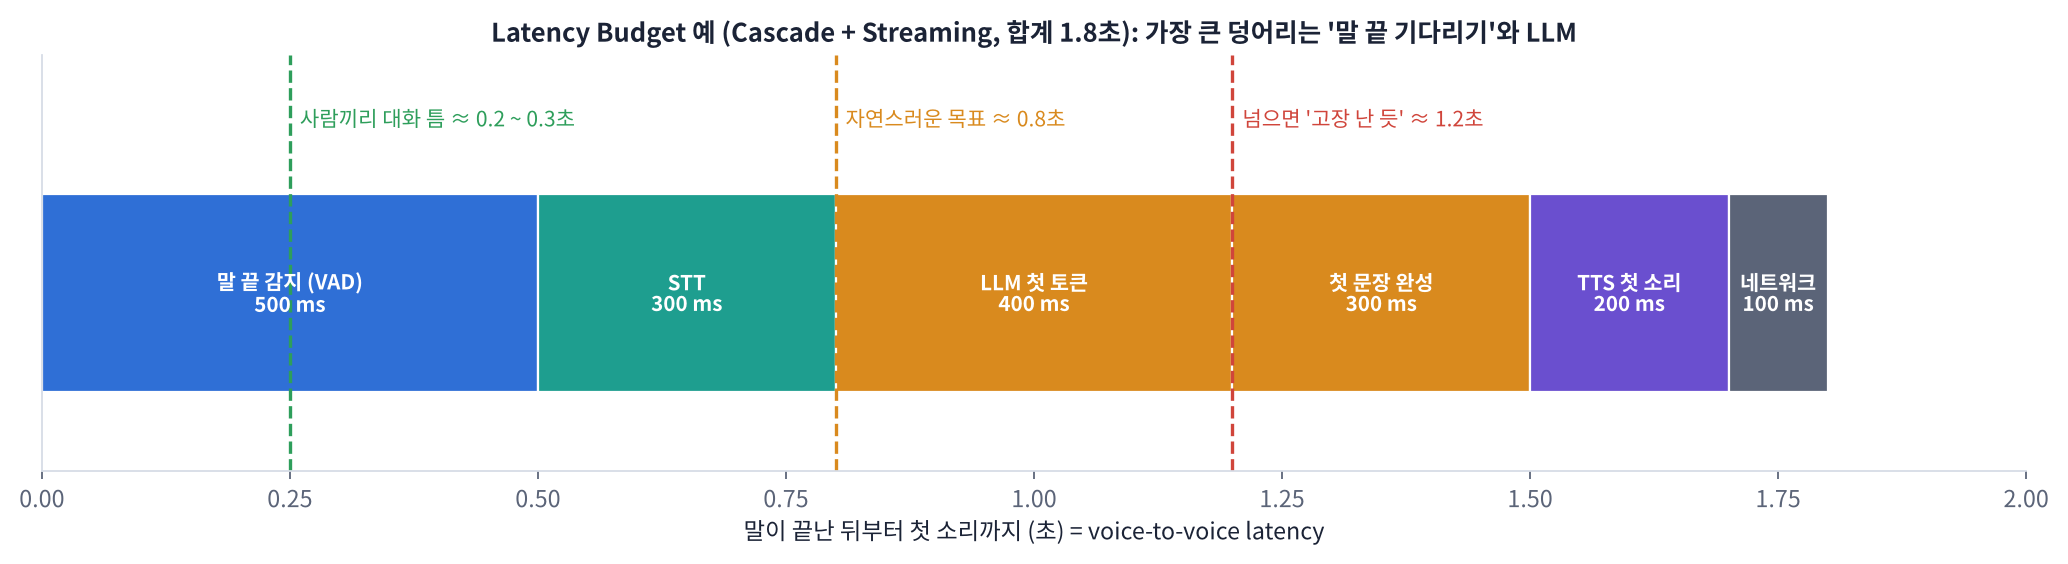

> 🍎 **비유: 택배 도착 약속.** "주문 후 1시간 안 도착"을 지키려면 포장 10분 · 상차 10분 · 이동 30분 · 배달 10분처럼 나눠 맡깁니다. 이동이 45분 걸리면 다른 단계를 아무리 줄여도 약속을 못 지킵니다. 음성 비서에서 '이동'에 해당하는 큰 덩어리가 **말 끝 기다리기**와 **LLM**입니다.

👣 **예산 세우는 순서**
1. 목표 정하기: 예) p50 ≤ 1.0초, p95 ≤ 1.5초 (말이 끝난 뒤 첫 소리까지)
2. 단계마다 한도 나누기: VAD · STT · LLM 첫 문장 · TTS 첫 소리 · 네트워크
3. 같은 조건에서 여러 번 재고 **중앙값(p50)과 느린 쪽(p95)** 을 함께 보기
4. 넘친 단계부터 줄이기: 더 작은 모델 · Streaming · 짧은 답 · 침묵 기준 · GPU · 데우기

> 📐 **핵심 식 하나: p95 = 100번 중 95번은 이보다 빠른 시간** — 평균은 몇 번의 아주 느린 응답을 숨깁니다. 사용자는 **가장 느렸던 몇 번**을 기억하므로 서비스 목표는 보통 p95(또는 p90)로 정합니다.

> 🎬 **애니메이션 D21-3:** [Latency Budget 설계기](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#budget) — 단계별 시간을 바꿔 합계가 0.8 · 1.2초 선을 넘는지 보기
> 🎬 **애니메이션 D21-7:** [p50 · p95 읽기](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#pct) — 가끔 느린 응답이 평균 · p50 · p95에 주는 영향 보기

> ## 🎤 강사 스크립트 · Part 3 Latency Budget  ⏱️ 8분
>
> 🎯 **목표를 단계별 한도로 나누고, p95로 판정한다.**
>
> 🖥️ [D21-3 예산 설계기](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#budget): 단계 슬라이더 → 합계가 0.8 · 1.2 선을 넘는 지점. "Streaming 켜기" 토글로 LLM 칸이 '첫 문장'으로 줄어드는 것.
>
> 🖥️ [D21-7 p50 · p95](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#pct): '가끔 느림' 비율을 올리면 평균 · p50은 그대로인데 p95만 튀는 것.
>
> 🗣️ "평균 1초인 비서가 20번에 한 번 5초 걸리면, 사용자는 그 5초를 기억합니다."

### 🧩 빈칸 실습 4 · 5: 예산 합계와 p95
- 빈칸 4: 예산 사전 `BUDGET`의 **값들만** 꺼내 더하는 사전 메서드 이름
- 빈칸 5: 느린 쪽 기준 지연, **몇 번째 백분위수**인지 (숫자)

> ## 🎤 강사 스크립트 · 빈칸 실습 4 · 5  ⏱️ 12분
>
> 🆘 빈칸 4: "사전의 값만 꺼내는 메서드, keys / values / items 중" → `values`
> 🆘 빈칸 5: "느린 쪽 기준 백분위수" → `95`
>
> ✅ 예상 출력: 판정표 4줄(대개 llm ❌ 넘침, 나머지 ✅), `예산 합계 1.50초 · 측정 p50 2.x초 · p95 3.x초`, 점 그래프, `✅`.
>
> ⚠️ "6번으로 p95를 말하는 건 무리" — 꼭 짚기. 실제는 수백 턴.

In [ ]:
# 🧩 빈칸 실습 4 · 5
BUDGET = {"endpoint": 0.50, "stt": 0.30, "llm": 0.50, "tts": 0.20}    # ✏️ 단계별 한도 (초) · v1 기준 (LLM = 답 전체)
TOTAL = sum(BUDGET.____())                                                                 # 빈칸 4

RUNS = []                                                # 질문 3개 × 2번 = 6번 측정 (첫 번째 줄은 이미 데운 상태)
for rep in range(2):
    for u in USER_AUDIO:
        r = cascade_v1(u["y"])
        RUNS.append(dict(질문=u["text"][:12], 회=rep + 1, **{k: round(v, 3) for k, v in r["T"].items()}))
RUNS = pd.DataFrame(RUNS)
V2V = RUNS["v2v"].to_numpy()
p50, p95 = np.percentile(V2V, 50), np.percentile(V2V, ____)                                 # 빈칸 5

cmp = pd.DataFrame({"예산": pd.Series(BUDGET), "측정_p50": RUNS[list(BUDGET)].median(), "측정_최대": RUNS[list(BUDGET)].max()}).round(3)
cmp["판정"] = np.where(cmp["측정_p50"] <= cmp["예산"], "✅", "❌ 넘침")
display(cmp)
print(f"예산 합계 {TOTAL:.2f}초 · 측정 p50 {p50:.2f}초 · p95 {p95:.2f}초 · 평균 {V2V.mean():.2f}초 (n = {len(V2V)})")
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.plot(V2V, np.zeros_like(V2V) + np.random.default_rng(0).uniform(-0.1, 0.1, len(V2V)), "o", alpha=0.7)
for x, lab, col in [(p50, "p50", "tab:green"), (p95, "p95", "tab:red"), (TOTAL, "budget", "tab:orange")]:
    ax.axvline(x, color=col, ls="--"); ax.text(x, 0.25, lab, color=col)
ax.set_yticks([]); ax.set_ylim(-0.4, 0.4); ax.set_xlabel("voice-to-voice latency (s)"); plt.tight_layout(); plt.show()
check(abs(TOTAL - 1.5) < 1e-9 and abs(p95 - np.quantile(V2V, 0.95)) < 1e-9 and p95 >= p50,
      hint="빈칸 4 = values, 빈칸 5 = 95")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
TOTAL = sum(BUDGET.values())
p50, p95 = np.percentile(V2V, 50), np.percentile(V2V, 95)
```

**해설**: `dict.values()`는 값만, `keys()`는 이름만, `items()`는 (이름, 값) 쌍을 줍니다. `np.percentile(x, 95)`는 정렬했을 때 95% 지점의 값(사이 값은 보간)입니다. 오늘은 **6번만** 재서 p95는 사실상 '가장 느린 값 근처'일 뿐입니다. 실제 서비스는 수백 ~ 수천 번의 턴을 모아 p50 · p95 · p99를 대시보드로 봅니다(D28 Metrics, D34 모니터링). 판정표에서 ❌인 단계가 다음에 줄일 곳입니다. v1에서는 대개 **llm**(답 전체를 기다림)이 넘칩니다 → Part 4 Streaming에서는 LLM 예산을 '첫 문장까지'로 바꿉니다.

</details>

### 3-1. 답 길이 = 지연: 시스템 지시의 효과
LLM은 토큰을 하나씩 만들므로 **LLM 시간 ≈ 첫 토큰 시간 + 토큰 수 ÷ 초당 토큰 수** 입니다. 같은 질문에 '음성용 짧은 지시'와 '자세한 글 채팅용 지시'를 주고 토큰 수와 시간을 비교합니다.

> ## 🎤 강사 스크립트 · 답 길이 실험  ⏱️ 8분
>
> ✅ 예상 출력: 음성용 20 ~ 50토큰 · 1 ~ 2초, 글 채팅용 150 ~ 256토큰 · 5 ~ 9초. 초당 토큰 수는 거의 같음.
>
> 🖥️ [D21-8 답 길이 = 지연](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#length).
>
> ❓ 생각해 보기(0.5초 예산이면 몇 토큰?) → 약 10토큰 → 답 전체 기다리기는 불가능 → Streaming.

In [ ]:
LONG_SYSTEM = "너는 친절한 AI 비서야. 질문에 자세하고 풍부하게, 필요하면 목록과 예시를 들어 설명해."
rows = []
for name, system, cap in [("음성용 (짧게)", VOICE_SYSTEM, MAX_NEW), ("글 채팅용 (자세히)", LONG_SYSTEM, 256)]:
    for q in QUESTIONS[:2]:
        t = time.perf_counter()
        reply, n = llm_reply(build_messages(q, system=system), max_new_tokens=cap)
        sec = time.perf_counter() - t
        rows.append(dict(지시=name, 질문=q[:12], 토큰=n, LLM_초=round(sec, 2), 초당_토큰=round(n / sec, 1), 대답=reply[:70].replace("\n", " ")))
LEN = pd.DataFrame(rows)
display(LEN)
print(LEN.groupby("지시")[["토큰", "LLM_초"]].mean().round(2))

**결과 읽기**
- 초당 토큰 수(T4 + 1.7B 모델이면 대략 20 ~ 40)는 거의 같고, **토큰 수가 늘어난 만큼 시간이 늘어납니다**.
- 글 채팅용 답에는 목록 기호 · 마크다운이 섞여 소리로 읽기도 어색합니다. 음성 비서의 시스템 지시가 **'짧게 · 구어체'** 인 이유가 지연과 듣기 두 가지 모두입니다(D22에서 더 다듬음).

**❓ 생각해 보기**: v1에서 LLM 예산 0.5초를 지키려면 답이 몇 토큰 이하여야 할까요? (첫 토큰 0.15초, 초당 30토큰이라고 가정) 그래도 부족하면?

<details>
<summary>답 보기</summary>

(0.5 − 0.15) × 30 ≈ **10토큰** 정도로, 한국어 한 문장도 어렵습니다. 그래서 '답 전체를 기다리는' v1으로는 예산을 지키기 어렵고, **첫 문장만 완성되면 바로 말하기 시작**하는 Streaming(Part 4)으로 예산의 기준을 '답 전체'에서 '첫 문장'으로 바꿉니다. 그 밖에: 더 작은 · 빠른 모델, 빠른 API(D22), 짧은 확인 멘트를 먼저 말하기('네, 확인해 볼게요').

</details>

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html)** — Latency Budget, 사람 대화의 틈, p50 · p95, 답 길이와 LLM 시간, 예산 넘침 진단
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 2교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html). 자주 틀리는 문항: **p95의 뜻**, **평균이 숨기는 것**, **LLM 시간 ∝ 토큰 수**.

## Part 4. Cascade v2: LLM 토큰을 흘려보내며 문장마다 TTS

> 💬 **쉽게 말하면**: LLM이 답을 **다 쓸 때까지 기다리지 않습니다**. 토큰이 나오는 대로 받아 모으다가 **문장이 하나 완성되면 바로 TTS** 로 보내 말하기 시작합니다. 비서가 첫 문장을 말하는 동안 LLM은 뒤 문장을 계속 씁니다.

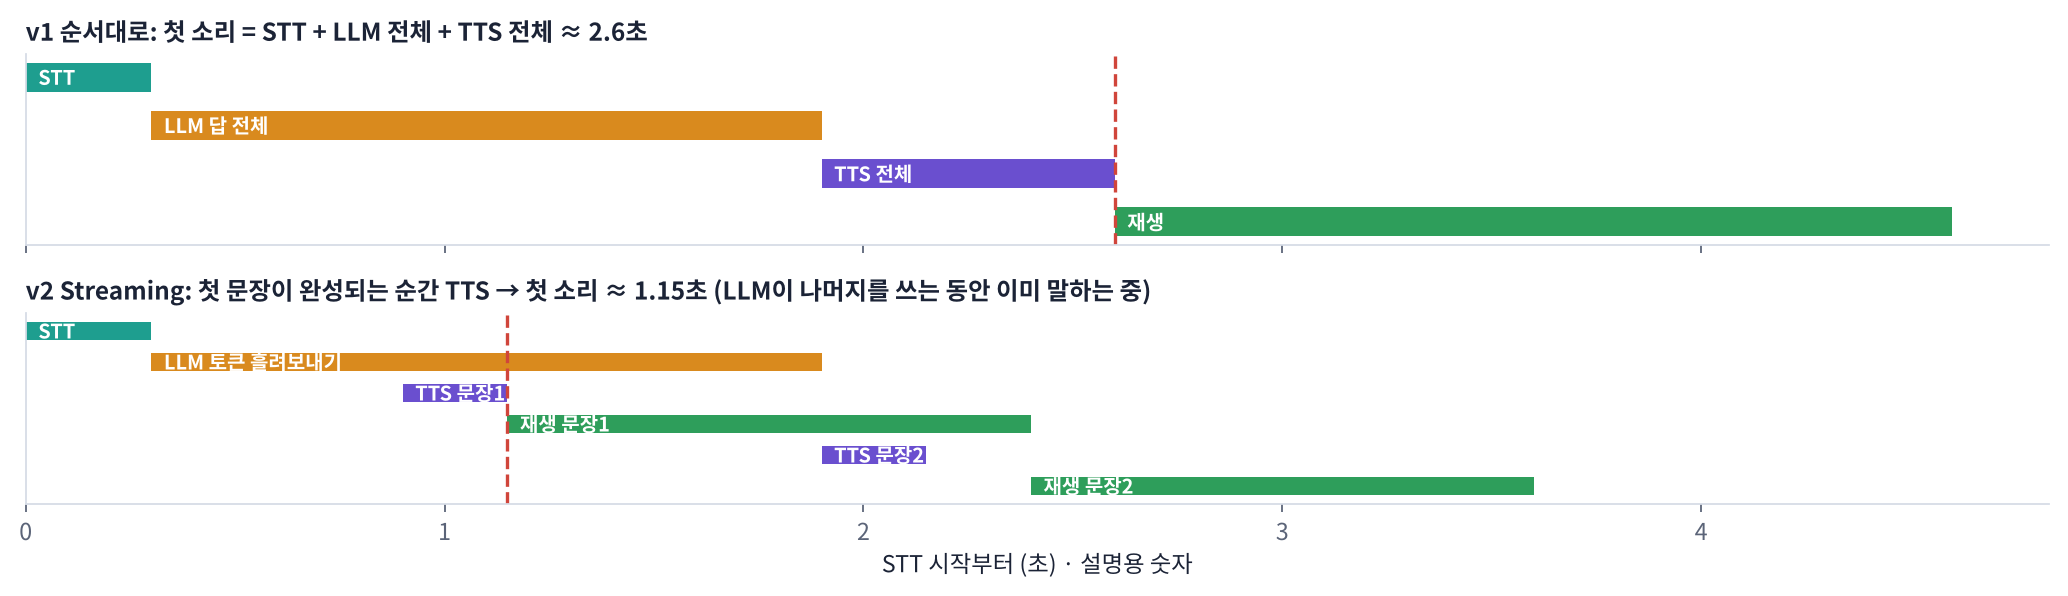

👣 **Streaming 한 단계씩**
1. LLM `generate()`를 **다른 스레드**에서 시작 (그래야 기다리지 않고 토큰을 받을 수 있음)
2. `TextIteratorStreamer`가 새 토큰 조각을 하나씩 넘겨줌 → 첫 조각이 나온 시각 = **TTFT(Time To First Token)**
3. 조각을 버퍼에 이어 붙이다가 **문장 끝(. ! ? 뒤 띄어쓰기)** 이 나오고 충분히 길면 그 문장을 내보냄
4. 문장마다 TTS → 첫 문장의 소리가 준비된 시각 = **TTFA**(D17 · D20)
5. 마지막에 버퍼에 남은 글도 내보냄

> 📐 **핵심 식 하나: v2 지연 = 말 끝 감지 + STT + (첫 문장 완성 시각) + TTS(첫 문장)** — 'LLM 답 전체'가 '첫 문장'으로 바뀝니다.

> 🍎 **비유: 식당 코스 요리.** 모든 요리가 다 될 때까지 기다렸다 한 번에 내지 않고, **전채가 되면 바로** 냅니다. 손님이 전채를 먹는 동안 주방은 본 요리를 만듭니다.

> 🎬 **애니메이션 D21-4:** [v1 vs v2 타임라인](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#pipeline) — 토큰 속도 · 문장 길이 · TTS 속도를 바꿔 첫 소리 시간 비교

> ## 🎤 강사 스크립트 · Part 4 Streaming  ⏱️ 6분
>
> 🎯 **'답 전체'를 기다리지 않고 '첫 문장'에서 말하기 시작한다.**
>
> 🖥️ [D21-4 v1 vs v2 타임라인](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#pipeline): 토큰 속도 · 첫 문장 길이 슬라이더 → 첫 소리 시각 비교. "첫 문장이 짧을수록 빨라진다."
>
> 🍎 코스 요리.

### 🧩 빈칸 실습 6 · 7 · 8: 토큰 흘려보내기 · TTFT · 문장 자르기
- 빈칸 6: 만든 스레드를 **실행 시작**하는 메서드 이름 (`Thread` 객체의 메서드)
- 빈칸 7: TTFT = 첫 조각이 도착한 시각 − **LLM을 시작한 시각을 담은 변수**
- 빈칸 8: 너무 짧은 조각('네.')을 따로 보내면 TTS 호출만 늘고 어색하므로, 문장 끝을 **`min_chars` 글자 이후부터** 찾습니다. 정규식 `search(문자열, 시작위치)`의 시작 위치에 들어갈 변수

> ## 🎤 강사 스크립트 · 빈칸 실습 6 · 7 · 8  ⏱️ 15분
>
> 🆘 빈칸 6: "스레드를 실제로 돌리는 메서드" → `start` (`run`은 지금 스레드에서 실행돼 Streaming이 안 됨)
> 🆘 빈칸 7: "LLM을 시작할 때 시각을 담은 변수, 바로 위 줄" → `t_llm`
> 🆘 빈칸 8: "몇 글자 뒤부터 문장 끝을 찾을지, 함수 인자" → `min_chars`
>
> ✅ 예상 출력: `문장 자르기 테스트: ['안녕하세요. 네.', '오늘은 맑아요!', '내일도 좋아요.']`, 문장 표 1 ~ 3줄, `ttft 0.05 ~ 0.2`, `first_sentence 0.4 ~ 1.0`, `✅`.
>
> ❓ "왜 '3.5'에서 자르지 않나?" → 마침표 뒤 띄어쓰기 조건.

In [ ]:
# 🧩 빈칸 실습 6 · 7 · 8
END = re.compile(r"[.!?。…~]+\s")                       # 문장 끝 = 마침표 · 물음표 · 느낌표 뒤 띄어쓰기
MIN_CHARS = 8

def llm_stream(messages, max_new_tokens=MAX_NEW):
    enc = llm_inputs(messages)
    streamer = TextIteratorStreamer(tok, skip_prompt=True, skip_special_tokens=True)
    th = Thread(target=llm.generate, kwargs=dict(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                                 repetition_penalty=1.1, streamer=streamer))
    th.____()                                                                             # 빈칸 6
    for piece in streamer:
        yield piece
    th.join()

def sentences(pieces, min_chars=MIN_CHARS):
    buf = ""
    for p in pieces:
        buf += p
        while (m := END.search(buf, ____)):                                                # 빈칸 8
            yield buf[:m.end()].strip()
            buf = buf[m.end():]
    if buf.strip():
        yield buf.strip()

def cascade_v2(y, min_silence_ms=500, history=()):
    T, chunks = {}, []
    ends = endpoint(y, min_silence_ms)
    end = ends[0] if ends else dict(detected=len(y) / SR, speech_end=len(y) / SR)
    T["endpoint"] = end["detected"] - end["speech_end"]
    with stage(T, "stt"):
        heard = stt(y[: int(end["detected"] * SR)])
    t_llm, ttft = time.perf_counter(), None
    def pieces():
        nonlocal ttft
        for p in llm_stream(build_messages(heard, history)):
            if ttft is None and p.strip():
                ttft = time.perf_counter() - ____                                          # 빈칸 7
            yield p
    for sent in sentences(pieces()):
        done = time.perf_counter() - t_llm
        a = tts(sent)
        chunks.append(dict(문장=sent, 문장_완성=round(done, 3), 소리_준비=round(time.perf_counter() - t_llm, 3), 길이=round(len(a) / SR, 2), audio=a))
    T["ttft"] = ttft if ttft is not None else float("nan")
    T["first_sentence"] = chunks[0]["문장_완성"]
    T["tts_first"] = chunks[0]["소리_준비"] - chunks[0]["문장_완성"]
    T["v2v"] = T["endpoint"] + T["stt"] + chunks[0]["소리_준비"]
    return dict(heard=heard, chunks=chunks, T=T)

test = list(sentences(iter(["안녕하세요. ", "네. 오늘은 ", "맑아요! 내일도", " 좋아요."]), min_chars=6))
print("문장 자르기 테스트:", test)
r2 = cascade_v2(USER_AUDIO[0]["y"])
display(pd.DataFrame(r2["chunks"]).drop(columns="audio"))
print({k: round(v, 3) for k, v in r2["T"].items()})
play(np.concatenate([c["audio"] for c in r2["chunks"]]), SR, "🤖 v2 대답 (문장 이어 붙임)")
check(test == ["안녕하세요. 네.", "오늘은 맑아요!", "내일도 좋아요."] and 0 < r2["T"]["ttft"] <= r2["T"]["first_sentence"] + 1e-6,
      hint="빈칸 6 = start, 빈칸 7 = t_llm, 빈칸 8 = min_chars")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
th.start()
while (m := END.search(buf, min_chars)):
ttft = time.perf_counter() - t_llm
```

**해설**: `Thread(target=...)`는 일을 맡길 준비만 하고, **`start()`** 를 불러야 실제로 다른 스레드에서 실행됩니다(`run()`을 직접 부르면 지금 스레드에서 끝까지 실행돼 Streaming이 되지 않습니다). 생성은 다른 스레드에서, 토큰 받기 · 문장 자르기 · TTS는 지금 스레드에서 동시에 진행됩니다. `END.search(buf, min_chars)`는 앞 `min_chars`글자 안의 마침표는 무시하므로 '네.' 같은 아주 짧은 조각이 따로 나가지 않습니다(테스트의 첫 결과가 '안녕하세요. 네.'로 묶인 이유). 띄어쓰기를 문장 끝 조건에 넣은 이유: '3.5'처럼 **숫자 속 마침표**에서 자르지 않으려고. TTFT는 'LLM을 부른 순간'부터 첫 글자가 나온 순간까지이며, 입력(시스템 지시 + 이력)이 길수록 늘어납니다.

</details>

In [ ]:
# v1 vs v2 같은 질문 3개 비교
rows = []
for u in USER_AUDIO:
    a, b = cascade_v1(u["y"]), cascade_v2(u["y"])
    rows.append(dict(질문=u["text"][:14], v1_v2v=round(a["T"]["v2v"], 2), v2_v2v=round(b["T"]["v2v"], 2),
                     TTFT=round(b["T"]["ttft"], 2), 첫문장=round(b["T"]["first_sentence"], 2), LLM_전체_v1=round(a["T"]["llm"], 2),
                     문장수=len(b["chunks"]), 줄어든_초=round(a["T"]["v2v"] - b["T"]["v2v"], 2)))
CMP = pd.DataFrame(rows)
display(CMP)
fig, ax = plt.subplots(figsize=(8, 2.8))
x = np.arange(len(CMP)); ax.bar(x - 0.2, CMP.v1_v2v, 0.4, label="v1 sequential"); ax.bar(x + 0.2, CMP.v2_v2v, 0.4, label="v2 streaming")
ax.axhline(0.8, color="green", ls="--"); ax.axhline(1.2, color="red", ls="--"); ax.set_xticks(x); ax.set_xticklabels([f"Q{i + 1}" for i in x])
ax.set_ylabel("voice-to-voice (s)"); ax.legend(); plt.tight_layout(); plt.show()

> ## 🎤 강사 스크립트 · v1 vs v2 비교  ⏱️ 6분
>
> ✅ 예상 출력: 여러 문장 답에서 0.5 ~ 2초 줄어듦, 한 문장 답은 거의 같음.
>
> ⚠️ v2가 조금 느린 질문이 있어도 정상: 답이 한 문장이면 이득이 없고, LLM과 TTS가 GPU를 나눠 씀.

**결과 읽기**
- 답이 여러 문장일수록 v2의 이득이 큽니다(`문장수`가 1이면 v1과 거의 같음: 첫 문장 = 답 전체).
- 그래도 **말 끝 기다리기(0.5초) + STT** 는 그대로 남습니다. 이 부분은 Part 5(침묵 기준)와 6주차(스트리밍 STT · 끼어들기)에서 다룹니다.
- 실제 서비스는 문장 단위보다 더 잘게(쉼표 · 구 단위) 자르거나, TTS도 Streaming으로 첫 소리를 더 당깁니다(D17 Kokoro, D27 Pipecat).

**❓ 생각해 보기**: v2에서 첫 문장을 말하는 동안 사용자가 '아니 그거 말고'라고 끼어들면 무엇이 필요할까요?

<details>
<summary>답 보기</summary>

① 비서가 말하는 중에도 **마이크를 계속 듣는 VAD** ② 사용자의 말이 감지되면 **재생 중지 + LLM 생성 중단**(이미 만든 토큰 · 소리 버리기) ③ 비서가 **어디까지 말했는지**를 대화 이력에 남기기(못 들은 뒷부분은 이력에서 빼야 함) ④ 비서 자신의 목소리를 사용자 말로 착각하지 않게 **에코 제거(AEC)**. 이것이 **Barge-in(끼어들기)** 이고 D28 Pipecat 심화에서 구현합니다. S2S 모델은 이 부분을 모델 안에서 자연스럽게 처리하는 것이 큰 장점입니다.

</details>

> ## 🎤 강사 스크립트 · 결과 읽기 · Barge-in 예고  ⏱️ 4분
>
> ❓ 생각해 보기(끼어들기) → 계속 듣는 VAD · 재생 중지 · 생성 중단 · 이력 정리 · 에코 제거 → D28.

## Part 5. VAD Endpointing: 기다림과 말 잘림의 줄다리기

> 💬 **쉽게 말하면**: 사람은 말하다가 "음…", "그러니까," 하고 잠깐 쉽니다. 침묵 기준을 **짧게** 하면 빨리 대답하지만 **말을 중간에 끊고** 끼어들고, **길게** 하면 끊지는 않지만 **매번 그만큼 늦게** 대답합니다.

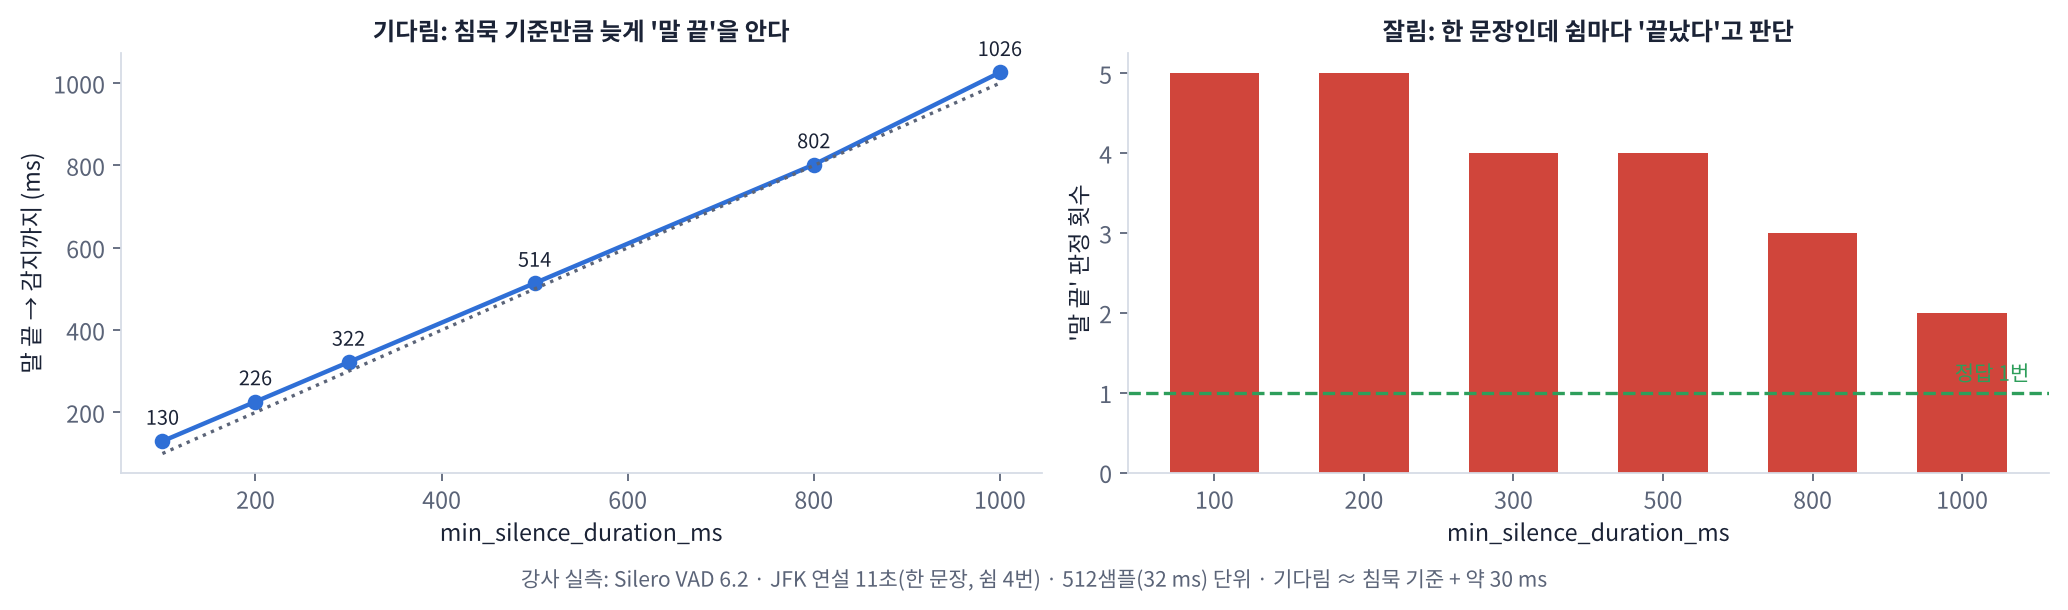

> 🍎 **비유: 눈치 보는 대화 상대.** 상대가 숨만 쉬어도 바로 말을 받는 사람은 빠르지만 말을 자주 끊고, 3초씩 기다리는 사람은 끊지는 않지만 답답합니다.

👣 **실험 순서**: 한 문장 안에 **0.6초 쉼**이 있는 사용자 말("내일 아침에, … 서울 날씨 알려 줘")을 만들고, 침묵 기준을 200 ~ 1000 ms로 바꾸며 ① 첫 '말 끝'이 실제 끝보다 **앞에서**(쉼에서) 나오는지(= 잘림) ② 실제 끝에서 나왔다면 **얼마나 기다렸는지** 를 봅니다.

> 🎬 **애니메이션 D21-5:** [VAD 말 끝 감지](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#vad) — 쉼 길이와 침묵 기준을 바꿔 잘림 · 기다림 보기

> ## 🎤 강사 스크립트 · Part 5 Endpointing  ⏱️ 5분
>
> 🎯 **침묵 기준: 짧으면 잘리고, 길면 늦다.**
>
> 🖥️ [D21-5 VAD 말 끝 감지](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#vad): '쉼 있는 문장' 프리셋 → 기준 300 / 800 비교.
>
> 🗣️ "제가 JFK 연설 11초로 재 봤습니다. 한 문장인데 기준 100 ms면 '끝났다'를 5번, 1000 ms에서도 2번 판정합니다."

In [ ]:
# ✏️ 쉼이 들어간 한 문장 만들기 · 침묵 기준 바꾸며 실험
PART_A, PART_B, PAUSE = "내일 아침에", "서울 날씨 알려 줘.", 0.6                     # ✏️ 쉼 길이(초)를 바꿔 보세요
a = librosa.effects.pitch_shift(tts(PART_A, seed=61), sr=SR, n_steps=-3)
b = librosa.effects.pitch_shift(tts(PART_B, seed=62), sr=SR, n_steps=-3)
PAUSED = np.concatenate([silence(0.8), a, silence(PAUSE), b, silence(2.0)]).astype(np.float32)
TRUE_END = (len(PAUSED) - 2.0 * SR) / SR                  # 실제 말이 끝난 시각 (뒤 침묵 2초 전)
play(PAUSED, SR, f"'{PART_A}' … ({PAUSE}초 쉼) … '{PART_B}'")

rows = []
for ms in [200, 300, 500, 800, 1000]:
    ends = endpoint(PAUSED, ms)
    first = ends[0] if ends else None
    cut = bool(first) and first["speech_end"] < TRUE_END - 0.3
    rows.append(dict(침묵_기준_ms=ms, 말끝_판정_횟수=len(ends), 첫_판정_시각=round(first["detected"], 2) if first else None,
                     잘림=cut, 기다림_초=None if (cut or not first) else round(first["detected"] - first["speech_end"], 3)))
VADT = pd.DataFrame(rows)
display(VADT)
print(f"실제 말 끝: {TRUE_END:.2f}초 · 잘림 = 첫 '말 끝'이 쉼 위치에서 나옴 → 비서가 '내일 아침에'만 듣고 대답 시작")

> ## 🎤 강사 스크립트 · 침묵 기준 실험  ⏱️ 10분
>
> ✅ 예상 출력: 200 · 300 ms → `잘림=True`(쉼 0.6초에서 판정), 800 · 1000 ms → `잘림=False`, 기다림 ≈ 0.8 · 1.0초. 500 ms는 경계(쉼 0.6초보다 짧아 대개 잘림).
>
> 🎧 잘린 경우 STT 결과('내일 아침에')와 끝까지 기다린 경우 비교.
>
> ❓ 생각해 보기(카드 번호) → 대화 상태별 VAD 설정 · 슬롯 채우기 · DTMF · 확인.

In [ ]:
# 잘린 경우 STT가 듣는 것 vs 끝까지 기다린 경우
for ms in [300, 800]:
    ends = endpoint(PAUSED, ms)
    cut_at = ends[0]["detected"] if ends else len(PAUSED) / SR
    print(f"침묵 기준 {ms} ms → {cut_at:.2f}초에서 턴 종료 → STT: '{stt(PAUSED[: int(cut_at * SR)])}'")

**결과 읽기**
- 침묵 기준이 쉼(0.6초)보다 짧으면 첫 '말 끝'이 쉼에서 나옵니다 → **잘림**. 비서는 '내일 아침에'만 듣고 엉뚱하게 대답하거나, 사용자가 이어 말하는 순간 **서로 겹쳐 말하게** 됩니다.
- 쉼보다 길게 하면 잘리지 않지만, **모든 턴에서 그만큼 늦게** 대답합니다(기다림 ≈ 기준 + 30 ms).
- 강사 실측(JFK 연설 한 문장, 쉼 4번): 기준 100 · 200 ms → 말 끝 5번, 300 · 500 → 4번, 800 → 3번, 1000 → 2번. **한 문장인데도 1000 ms에서조차 한 번 잘렸습니다**.

| 대책 | 방법 | 배우는 날 |
|---|---|---|
| 상황별 기준 | 짧은 답(예/아니요) 질문 뒤에는 짧게, 주소 · 번호를 부를 때는 길게 | D28 |
| 의미로 판단 (Semantic Turn Detection) | "내일 아침에,"처럼 **말이 덜 끝난 글**이면 더 기다림 (작은 언어 모델 · 전용 모델) | D28 · D29 |
| 미리 준비 (Speculative) | 짧은 침묵에서 **STT · LLM을 미리 시작**하고, 사용자가 이어 말하면 버림 | D28 |
| 끼어들기 허용 (Barge-in) | 늦게 잘리더라도 사용자가 다시 말하면 비서가 멈춤 | D28 |

**❓ 생각해 보기**: 콜센터에서 고객이 카드 번호 16자리를 4자리씩 끊어 부릅니다. 침묵 기준 300 ms면 어떻게 되고, 어떻게 설계하면 좋을까요?

<details>
<summary>답 보기</summary>

4자리마다 쉬므로 **매번 턴이 끝났다고 판단**해 비서가 중간에 끼어듭니다. 설계: ① '카드 번호를 말씀해 주세요' 상태에서는 침묵 기준을 1.5 ~ 2초로 늘리기(대화 상태별 VAD 설정) ② 숫자가 16자리 모일 때까지 STT 결과를 쌓고 LLM을 부르지 않기(규칙 기반 슬롯 채우기) ③ 키패드(DTMF) 입력 병행 ④ 다 모이면 '○○○○로 끝나는 카드 맞으시죠?' 확인. 민감 정보는 로그에서 가리기(D34).

</details>

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html)** — Streaming 단계, 스레드 start, TTFT · TTFA, 문장 자르기 규칙, 침묵 기준의 줄다리기, Semantic Turn Detection · Barge-in
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 3교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html). 자주 틀리는 문항: **start vs run**, **TTFT vs TTFA**, **침묵 기준 줄다리기 방향**.

## Part 6. Cascade vs S2S: 무엇을 고를까

> 💬 **쉽게 말하면**: 정답 구조는 없습니다. **무엇이 가장 중요한지**(빠름 · 감정 · 기록 · 도구 · 한국어 · 비용 · 개인정보)에 가중치를 주고 고릅니다. 같은 회사라도 서비스마다 답이 다릅니다.

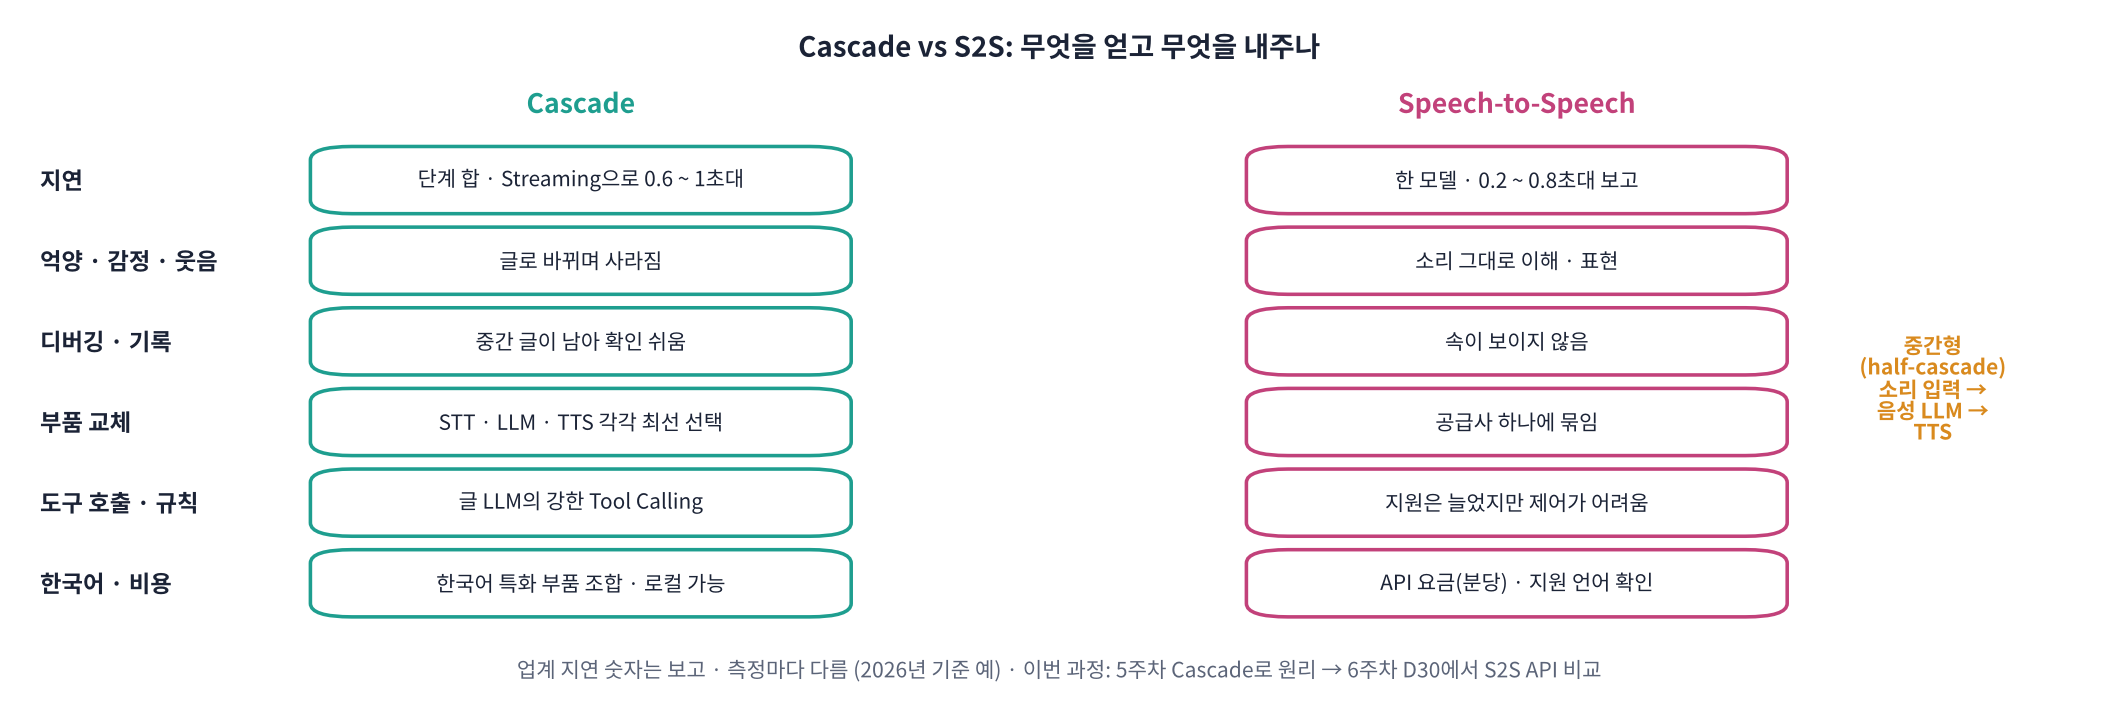

| 기준 | Cascade (로컬 부품) | Cascade (API 부품) | S2S (API) |
|---|---|---|---|
| 지연 | 1 ~ 2초 (오늘 T4) · 최적화로 1초 안쪽 | 0.6 ~ 1.2초 보고 | 0.2 ~ 0.8초 보고 (도구 호출 · 긴 추론 시 늘어남) |
| 억양 · 감정 | 사라짐 | 사라짐 | 듣고 표현함 |
| 디버깅 · 감사 기록 | 글이 남음 | 글이 남음 | 따로 받아쓰기 필요 |
| 도구 호출 · 규칙 | 강함 (D23 · D24) | 강함 | 지원되지만 제어 · 검증이 어려움 |
| 한국어 | 부품마다 한국어 특화 선택 가능 | 상용 STT · TTS 한국어 선택 | 모델마다 지원 확인 |
| 비용 | GPU 서버 | 부품별 사용량 요금 | 분당 · 오디오 토큰 요금 |
| 개인정보 | 내 서버 안에서 처리 | 외부 전송 | 외부 전송 |

> ⚠️ 지연 숫자는 업계 보고 · 벤치마크 예(2026년)이며 지역 · 모델 · 측정 방법에 따라 크게 다릅니다. 6주차 D30에서 S2S API를 직접 재 봅니다.

> 🎬 **애니메이션 D21-9:** [아키텍처 선택기](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#choose) — 기준별 가중치를 바꿔 어떤 구조가 고르는지 보기

> ## 🎤 강사 스크립트 · Part 6 Cascade vs S2S 선택  ⏱️ 6분
>
> 🎯 **정답 구조는 없다. 무엇을 중요하게 여기는지가 구조를 정한다.**
>
> 🖥️ [D21-9 아키텍처 선택기](https://imguru-mooc.github.io/AI_Voice/day21/animation.html#choose): 상황 프리셋(콜센터 · 회화 튜터 …)을 눌러 선택이 바뀌는 것.
>
> ⚠️ 표의 지연 숫자는 업계 보고 예. "D30에서 직접 재 봅시다."

### 🧩 빈칸 실습 9: 가중치로 아키텍처 고르기
`choose()`는 기준마다 **가중치 × 구조의 점수**를 더해 가장 큰 구조를 고릅니다. `max(사전, key=...)`에서 **사전의 값으로 비교**하려면 사전의 어떤 메서드를 key로 주면 될까요?

> ## 🎤 강사 스크립트 · 빈칸 실습 9  ⏱️ 10분
>
> 🆘 "사전에서 키로 값을 꺼내는 메서드, 괄호 없이" → `get`
>
> ✅ 예상 출력: 선택표 — 병원 콜센터 · 말벗 · 현장 보고 → Cascade (로컬), 회화 튜터 → S2S (API), `✅`. 키오스크 → Cascade (API) + 민감도 경고 줄.
>
> ❓ "점수표가 맞나요?" → 토론. 팀 의견으로 숫자를 바꿔 보게 하기.

In [ ]:
# 🧩 빈칸 실습 9
ARCH = {   # 1 ~ 5점, 수업 토론용 상대 점수 (✏️ 팀 의견으로 바꿔도 됩니다)
    "Cascade (로컬)": dict(지연=2, 감정=1, 디버깅=5, 도구=5, 한국어=4, 비용=4, 개인정보=5),
    "Cascade (API)": dict(지연=3, 감정=2, 디버깅=5, 도구=5, 한국어=5, 비용=3, 개인정보=2),
    "S2S (API)":     dict(지연=5, 감정=5, 디버깅=2, 도구=3, 한국어=3, 비용=2, 개인정보=2),
}
SCENARIOS = {   # 기준별 가중치 0 ~ 3
    "병원 예약 콜센터":   dict(지연=2, 감정=1, 디버깅=3, 도구=3, 한국어=3, 비용=2, 개인정보=3),
    "외국어 회화 튜터":   dict(지연=3, 감정=3, 디버깅=1, 도구=0, 한국어=1, 비용=2, 개인정보=1),
    "어르신 말벗":       dict(지연=2, 감정=3, 디버깅=2, 도구=1, 한국어=3, 비용=1, 개인정보=3),
    "공장 현장 음성 보고": dict(지연=1, 감정=0, 디버깅=3, 도구=3, 한국어=3, 비용=2, 개인정보=3),
}

def choose(weights):
    scores = {name: sum(weights[k] * pts[k] for k in weights) for name, pts in ARCH.items()}
    return max(scores, key=scores.____), scores                                            # 빈칸 9

rows = []
for sc, w in SCENARIOS.items():
    best, scores = choose(w)
    rows.append(dict(상황=sc, 선택=best, **scores))
CHOICE = pd.DataFrame(rows).set_index("상황")
display(CHOICE)
best, scores = choose(SCENARIOS["외국어 회화 튜터"])
check(best == max(scores.items(), key=lambda kv: kv[1])[0] and CHOICE.loc["병원 예약 콜센터", "선택"].startswith("Cascade"),
      hint="빈칸 9 = get")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return max(scores, key=scores.get), scores
```

**해설**: `max(사전)`은 기본으로 **키(이름)** 를 비교합니다(가나다순으로 가장 큰 이름). `key=scores.get`을 주면 각 키를 `scores.get(키)` = **점수**로 바꿔 비교하므로 점수가 가장 큰 구조의 이름이 나옵니다. 결과 예: 병원 예약 콜센터 · 현장 보고 → **Cascade**(기록 · 도구 · 개인정보), 회화 튜터 → **S2S**(빠름 · 억양). 점수표 자체가 토론 대상입니다. 숫자 하나 바꾸면 결론이 바뀌는지(민감도)도 확인하세요. 실제로는 **중간형**(소리를 직접 듣는 음성 LLM + 글 기반 도구 호출 + 좋은 TTS)도 많이 씁니다.

</details>

In [ ]:
# ✏️ 우리 팀의 서비스 (최종 프로젝트 후보)를 가중치로 표현해 보기
MY_SERVICE = "키오스크 음성 주문"                           # ✏️
MY_WEIGHTS = dict(지연=3, 감정=0, 디버깅=2, 도구=3, 한국어=3, 비용=2, 개인정보=1)   # ✏️ 0 ~ 3
best, scores = choose(MY_WEIGHTS)
print(f"{MY_SERVICE} → {best}"); print({k: v for k, v in sorted(scores.items(), key=lambda kv: -kv[1])})
for k in MY_WEIGHTS:                                     # 민감도: 가중치 하나를 1 올리면 선택이 바뀌나?
    w2 = dict(MY_WEIGHTS); w2[k] += 1
    b2, _ = choose(w2)
    if b2 != best: print(f"  ⚠️ '{k}' 가중치를 1 올리면 → {b2} 로 바뀜")

**❓ 생각해 보기**: 최종 프로젝트 주제 예시(AI 콜센터 · 키오스크 주문 · 회화 튜터 · 어르신 말벗 · 현장 안전 보고) 중 하나를 골라, Latency Budget 표와 구조를 한 장으로 그려 본다면?

<details>
<summary>답 보기</summary>

예) **키오스크 음성 주문**: 구조 = 로컬 VAD + 스트리밍 STT + API LLM(메뉴 · 주문 Tool Calling) + 빠른 TTS. 예산(p95 1.2초) = 말 끝 0.4(주변 소음 → VAD 기준 짧게 + 버튼 보조) · STT 0.2 · LLM 첫 문장 0.4 · TTS 0.1 · 네트워크 0.1. 위험: 소음 · 여러 사람 동시 발화 → 마이크 방향 · 화면 확인 병행. 감정 표현은 덜 중요하므로 S2S보다 Cascade가 유리. 이 한 장이 **D36 아키텍처 · Latency 설계서**의 초안이 됩니다.

</details>

> ## 🎤 강사 스크립트 · 최종 프로젝트 연결  ⏱️ 5분
>
> 🗣️ "오늘 만든 한 장(구조 + 예산 + 선택 근거)이 8주차 D36 설계서의 초안입니다. 팀 후보 주제를 지금 하나 골라 보세요."

## Part 7. 정리 · 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| Voice Agent 부품 | VAD · STT · LLM · TTS | `endpoint` · `stt` · `llm_reply` · `tts` |
| 시간 재기 | 시작 시각을 빼고, GPU는 sync 후 | `time.perf_counter() - t_begin` |
| 말 끝 감지 | 침묵이 기준만큼 이어지면 end | `VADIterator(..., min_silence_duration_ms=min_silence_ms)` |
| 음성용 지시 | 짧게 · 구어체 · 기호 금지, 생각 모드 끔 | `{"role": "system", ...}`, `enable_thinking=False` |
| Latency Budget | 단계별 한도의 합 · p50 · p95 | `sum(BUDGET.values())`, `np.percentile(x, 95)` |
| Streaming | 다른 스레드에서 생성 · 문장마다 TTS | `th.start()`, `END.search(buf, min_chars)` |
| TTFT | LLM 시작부터 첫 토큰까지 | `time.perf_counter() - t_llm` |
| Endpointing | 짧으면 잘림 · 길면 늦음 | 침묵 기준 실험표 |
| 아키텍처 선택 | 가중치 × 점수, 민감도 확인 | `max(scores, key=scores.get)` |

### 📝 과제
1. **내 비서 측정 보고서**: 질문 5개로 v1 · v2를 각각 3번씩 돌려 단계별 p50 · p95 표와 예산 판정표를 만드세요. 예산을 넘은 단계 하나를 골라 줄이는 방법 2가지를 실험하고 결과를 적으세요(예: `MAX_NEW`, `MIN_CHARS`, 침묵 기준, Whisper 크기).
2. **침묵 기준 정하기**: 내 목소리(`USE_MIC = True`)로 쉼이 있는 문장 3개를 녹음해 Part 5 실험을 하고, 내 서비스에 맞는 기준(ms)과 그 이유를 3줄로 쓰세요.
3. **아키텍처 한 장**: 최종 프로젝트 후보 서비스 하나의 구조도 + Latency Budget 표 + Cascade/S2S 선택 근거(가중치표)를 노션에 정리하세요.

### ✅ 개념 워크시트 제출
> 📝 **[D21 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html)** — 4교시 × 10문항. 4개 탭 채점 → 제출 → 📋 캡처 → 노션에 붙이고, **v1 · v2 비교표 · 예산 판정표 · 침묵 기준 표 · 아키텍처 선택표**도 함께 붙이세요. 녹음 파일은 제출하지 않습니다.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day21/animation.html) — D21-1 ~ D21-9

### 다음 시간 (D22 · LLM API 연동)
오늘은 로컬 소형 LLM으로 구조와 지연을 봤습니다. 다음 시간에는 **Claude · OpenAI · Gemini API**를 연결해 답의 품질과 TTFT를 비교하고, 음성 대화용 프롬프트(짧은 응답 · 구어체 · 되묻기)와 **대화 이력 관리**를 다룹니다. API 키를 미리 준비해 Colab **보안 비밀(🔑)** 에 넣어 오세요.

> ## 🎤 강사 스크립트 · Part 7 정리 · D22 준비  ⏱️ 7분
>
> 🎯 **오늘 한 줄: 음성 비서는 '무엇을'만큼 '언제' 말하느냐 — 예산을 세우고, Streaming과 Endpointing으로 줄이고, 구조는 서비스가 중요하게 여기는 것으로 고른다.**
>
> 🖥️ [worksheet.html 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day21/worksheet.html) → 채점 → 제출 → 📋 캡처 → 노션(표만, 녹음 금지).
>
> ➡️ "다음 시간에는 Claude · OpenAI · Gemini API를 연결합니다. 키를 Colab 🔑 보안 비밀에 넣어 오세요. 코드에 키를 직접 쓰면 안 됩니다."